## Imports

In [1]:
%load_ext autoreload
%autoreload 2

from openaq_anomaly_prediction.load.gcp import bq
import warnings

from sklearn.base import BaseEstimator
from openaq_anomaly_prediction.core.xgboost import CustomXGBoostModel
from openaq_anomaly_prediction.core.timeseries_utils import tsu
from openaq_anomaly_prediction.config import Configuration as cfg
import os

import random
import tempfile
from pathlib import Path

import duckdb
import pandas as pd
from utilsforecast.plotting import plot_series
from utilsforecast.losses import rmse, mae, mape
from utilsforecast.evaluation import evaluate
import xgboost as xgb
import lightgbm as lgb
from mlforecast import MLForecast
from mlforecast.lag_transforms import ExpandingMean, RollingMean
from mlforecast.lag_transforms import (
    RollingMean,
    RollingStd,
    SeasonalRollingMean,
    SeasonalRollingStd,
    ExponentiallyWeightedMean,
    RollingMax,
    ExpandingStd,
)
from mlforecast.target_transforms import (
    Differences,
    LocalRobustScaler,
    LocalMinMaxScaler,
    LocalStandardScaler,
    LocalBoxCox,
)
from sklearn.preprocessing import FunctionTransformer

import mlforecast

import optuna
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ================================================================
# IMPORTS: python packages and settings (don't change anything)

import time
import requests
import gc
from typing_extensions import Literal

import duckdb
import numpy as np
import pandas as pd
# import pyarrow as pa
# import pyarrow.parquet as pq
# import pyarrow.dataset as ds
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from plotly.graph_objs import Figure as PlotlyFigure

from pprint import pprint

# CONFIG: to display all rows/columns of a dataframe (debug)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", 1000)
SEP_LENGTH = 64  # Only so we can print separators of a fixed length


In [6]:
KEPT_LOCATIONS = [
    "2623134",
    "2622745",
    "2622850",
    "2622996",
    "2623504",
    "2622780",
    "2622858",
    "2623424",
    "2623681",
    "2805678",
    "2622609",
    "2622825",
    "2622594",
    "2622855",
    "2623508",
    "2623488",
    "2622718",
    "2623048",
    "2623532",
    "2623170",
    "2623344",
    "2622917",
    "2623623",
    "2623711",
    "2622687",
    "2622689",
    "2623444",
    "2623394",
    "2623647",
    "2622606",
    "2622851",
    "2623586",
    "2622724",
    "2622608",
    "2623465",
    "2622627",
    "2622848",
    "2622837",
    "2623173",
    "2623536",
    "4872070",
    "2623679",
    "2623645",
    "2622793",
    "2622600",
    "2623720",
    "2623112",
    "2623579",
    "2623154",
    "4402010",
    "2623191",
    "2623557",
    "2622586",
    "2623590",
    "2623426",
    "2623078",
    "2623080",
    "2622950",
    "2622907",
    "2623422",
    "2623116",
    "2623198",
    "2622714",
    "2623114",
    "2623321",
    "2623474",
    "2622791",
    "2623718",
    "2623430",
    "2623069",
    "2623367",
    "2622807",
    "2623004",
    "2623190",
    "2623563",
    "2623345",
    "2622932",
    "2623440",
    "2622916",
    "2622796",
    "2623643",
    "4872069",
    "2622918",
    "2622744",
    "2623760",
    "2623582",
    "2623194",
    "2623537",
    "2623336",
    "2622727",
    "2623445",
    "2623186",
    "2622827",
    "4953358",
    "2623617",
    "2622782",
    "2623538",
    "2622860",
    "2622847",
    "2623052",
    "3916039",
    "2623277",
    "2623811",
    "2622675",
    "2622995",
    "2623259",
    "2623346",
    "2623115",
    "2622798",
    "2623442",
    "2623172",
    "2623214",
]

In [3]:
# # BigQuery
# start_time = time.perf_counter()
# query = """
#     SELECT
#         DISTINCT location_id
#     FROM `openaq-anomaly-prediction.dev_serving.ml_seoul__xgb_features`
#     WHERE datetimeto_utc <= '2025-10-31'
#       AND segment_total_hours >= 504
# """
# query_parameters = [
#     # ("dataset", "STRING", dataset)
# ]
# safe_location_ids = bq.query(query, query_parameters=query_parameters, dry_run=False)
# print(len(safe_location_ids["location_id"].tolist()))
# display(safe_location_ids["location_id"].tolist())

## Train

### Load the train dataset

In [5]:
# ================================================================
# LOAD THE ENTIRE DATASET (ALL LOCATIONS)

custom_xgb = CustomXGBoostModel()

# BigQuery
start_time = time.perf_counter()
query = """
    SELECT
        *
    FROM `openaq-anomaly-prediction.dev_serving.ml_seoul__xgb_features`
    WHERE datetimeto_utc <= '2025-10-31'
      AND segment_total_hours >= 504
    ORDER BY location_id, datetimeto_utc ASC
"""
query_parameters = [
    # ("dataset", "STRING", dataset)
]
train_df = bq.query(query, query_parameters=query_parameters, dry_run=False)
custom_xgb.categorize_columns(train_df)

# ================================================================
# INTERPOLATE ALL POLLUTANTS
 
train_df = custom_xgb.interpolate_pollutants(train_df, debug=True)
custom_xgb.print_nan_report(train_df)


# ================================================================
# COLUMNS CATEGORIZATION
 
display(train_df.head(5))
custom_xgb.print_categories_report()

INTERPOLATING 6 POLLUTANTS
----------------------------------------------------------------
BEFORE: 86755 total NaN values
    -> Adding columns       : ['pm25_ugm3_is_imputed', 'pm10_ugm3_is_imputed', 'no2_ppm_is_imputed', 'o3_ppm_is_imputed', 'so2_ppm_is_imputed', 'co_ppm_is_imputed', 'any_imputed']
    -> Grouped by           : ['location_id', 'segment_id']
    -> Linear interpolation : up to 4 hours
    -> Forward fill         : up to 4 hours
    -> Backward fill        : up to 4 hours
AFTER: 0 total NaN values

[ TARGET    ]: 0 NaN values in the target columns
[ OPENAQ    ]: 0 NaN values in OpenAQ columns
[ OPENMETEO ]: 0 NaN values in OpenMeteo columns
[ FEATURES  ]: 5824 NaN values in features columns
feat_weather__delta3_temperature_2m         2280
feat_weather__cooling_rate_1h                760
feat_weather__stagnation_cooling_index       760
feat_weather__lag1_precipitation             760
feat_weather__delta1_pressure_msl            760
feat_pollutant__expmean_co_ppm       

,location_id,datetimeto_utc,concurrent_sensors,segment_id,segment_start,segment_end,segment_perfect_hours,segment_total_hours,segment_perfect_density,segment_tier,segments_num,segments_total,pm25_ugm3,pm10_ugm3,no2_ppm,o3_ppm,so2_ppm,co_ppm,oaq_datetimeto_local,oaq_ismonitor,oaq_owner_id,oaq_provider_id,oaq_latitude,oaq_longitude,om_elevation,om_temperature_2m,om_relative_humidity_2m,om_dew_point_2m,om_precipitation,om_rain,om_snowfall,om_snow_depth,om_shortwave_radiation,om_direct_radiation,om_diffuse_radiation,om_weather_code,om_pressure_msl,om_cloud_cover,om_cloud_cover_low,om_cloud_cover_mid,om_cloud_cover_high,om_vapour_pressure_deficit,om_wind_speed_100m,om_wind_speed_10m,om_wind_gusts_10m,om_is_day,feat_time__hour,feat_time__dow,feat_time__month,feat_time__hour_sin_k1,feat_time__hour_cos_k1,feat_time__hour_sin_k2,feat_time__hour_cos_k2,feat_time__hour_sin_k3,feat_time__hour_cos_k3,feat_time__dow_sin_k1,feat_time__dow_cos_k1,feat_time__month_sin_k1,feat_time__month_cos_k1,feat_time__is_rush_hour,feat_time__is_weekend,feat_time__is_party_night,feat_time__is_evening_transition,feat_time__is_yellow_dust_season,feat_time__is_moonsoon_season,feat_time__is_winter_season,feat_time__is_summer_break,feat_time__is_winter_break,feat_time__is_spring_break,feat_time__is_school_break,feat_pollutant__expmean_pm25_ugm3,feat_pollutant__expmean_pm10_ugm3,feat_pollutant__expmean_no2_ppm,feat_pollutant__expmean_o3_ppm,feat_pollutant__expmean_so2_ppm,feat_pollutant__expmean_co_ppm,feat_pollutant__roll720_mean_pm25_ugm3,feat_pollutant__roll720_mean_pm10_ugm3,feat_pollutant__roll720_mean_no2_ppm,feat_pollutant__roll720_mean_o3_ppm,feat_pollutant__roll720_mean_so2_ppm,feat_pollutant__roll720_mean_co_ppm,feat_weather__wind_u_10m,feat_weather__wind_v_10m,feat_weather__wind_shear_100m_10m,feat_weather__cooling_rate_1h,feat_weather__stagnation_cooling_index,feat_weather__washout_index,feat_weather__moisture_trap_index,feat_weather__atmos_stability_index,feat_weather__moisture_saturation_index,feat_weather__dew_point_depression,feat_weather__photolytic_flux_index,feat_weather__wind_burst_ratio_index_10m,feat_weather__lag1_precipitation,feat_weather__delta1_pressure_msl,feat_weather__delta3_temperature_2m,pm25_ugm3_is_imputed,pm10_ugm3_is_imputed,no2_ppm_is_imputed,o3_ppm_is_imputed,so2_ppm_is_imputed,co_ppm_is_imputed,any_imputed
0,2622586,2024-05-16 01:00:00+00:00,6,2622586_S2,2024-05-16 01:00:00+00:00,2024-07-04 05:00:00+00:00,1137,1181,0.962743,gold,2,62,5.0,23.000000,0.0184,0.024800,0.002500,0.400000,2024-05-16 10:00:00,True,4,69,37.580167,127.044856,20.0,13.2,68,7.5,0.0,0.0,0.0,0.0,673.0,503.0,170.0,0,1011.3,0,0,0,0,0.49,13.3,10.5,22.3,1,10,3,4,5.000000e-01,-0.866025,-8.660254e-01,0.500000,1.000000e+00,1.194340e-15,0.433884,-0.900969,0.866025,-0.5,0,0,0,0,1,0,0,0,0,0,0,15.183844,32.509749,0.022980,0.040603,0.002923,0.401176,15.183844,32.509749,0.022980,0.040603,0.002923,0.401176,-9.000257,5.407900,2.8,NaN,NaN,0.0,6549.371429,96.314286,1.694915,5.7,64819.514286,2.123810,NaN,NaN,NaN,0,0,0,0,0,0,0
1,2622586,2024-05-16 02:00:00+00:00,6,2622586_S2,2024-05-16 01:00:00+00:00,2024-07-04 05:00:00+00:00,1137,1181,0.962743,gold,2,62,10.0,27.000000,0.0166,0.029300,0.003000,0.390000,2024-05-16 11:00:00,True,4,69,37.580167,127.044856,20.0,15.1,60,7.2,0.0,0.0,0.0,0.0,812.0,630.0,182.0,0,1010.6,0,0,0,0,0.69,14.1,11.3,23.8,1,11,3,4,2.588190e-01,-0.965926,-5.000000e-01,0.866025,7.071068e-01,-7.071068e-01,0.433884,-0.900969,0.866025,-0.5,0,0,0,0,1,0,0,0,0,0,0,15.155556,32.483333,0.022967,0.040559,0.002922,0.401173,15.155556,32.483333,0.022967,0.040559,0.002922,0.401173,-9.685990,5.819930,2.8,1.9,0.168142,0.0,5366.017699,89.433628,1.265823,7.9,72620.106195,2.106195,0.0,-0.7,NaN,0,0,0,0,0,0,0
2,2622586,2024-05-16 03:00:00+00:00,0,2622586_S2,2024-05-16 01:00:00+00:00,2024-07-04 05:00:00+00:00,1137,1181,0.962743,gold,2,62,10.0,26.333333,0.0156,0.033833,0.002967,0.383333,2024-05-16 12:00:00,True,4,69,37.580167,127.044856,20.0,16.7,50,6.3,0.0,0.0,0.0,0.0,899.0,707.0,19

COLUMNS CATEGORIZATION

Pollutants columns (6):
['pm25_ugm3', 'pm10_ugm3', 'no2_ppm', 'o3_ppm', 'so2_ppm', 'co_ppm']

OpenAQ columns (6):
['oaq_datetimeto_local', 'oaq_ismonitor', 'oaq_owner_id', 'oaq_provider_id', 'oaq_latitude', 'oaq_longitude']

OpenMeteo columns (22):
['om_elevation', 'om_temperature_2m', 'om_relative_humidity_2m', 'om_dew_point_2m', 'om_precipitation', 'om_rain', 'om_snowfall', 'om_snow_depth', 'om_shortwave_radiation', 'om_direct_radiation', 'om_diffuse_radiation', 'om_weather_code', 'om_pressure_msl', 'om_cloud_cover', 'om_cloud_cover_low', 'om_cloud_cover_mid', 'om_cloud_cover_high', 'om_vapour_pressure_deficit', 'om_wind_speed_100m', 'om_wind_speed_10m', 'om_wind_gusts_10m', 'om_is_day']

Segments columns (9):
['segment_id', 'segment_start', 'segment_end', 'segment_perfect_hours', 'segment_total_hours', 'segment_perfect_density', 'segment_tier', 'segments_num', 'segments_total']

Features columns (51):
 > Time features (24)      : ['feat_time__hour', 'feat_tim

### Optuna

In [ ]:

from mlforecast.optimization import mlforecast_objective
from sklearn.metrics import root_mean_squared_error

# ================================================================
# OPTUNA GRID SEARCH

import warnings

# MLForecast warnings about the nulls in the exogenous features
warnings.filterwarnings("ignore", message="Found null values in")
warnings.filterwarnings("ignore", message="The following series are too short")
warnings.filterwarnings("ignore", message="The following series were dropped completely")

TARGET_COL = "pm25_ugm3"
# TARGET_COL = "pm10_ugm3"
# TARGET_COL = "no2_ppm"
# TARGET_COL = "o3_ppm"
# TARGET_COL = "so2_ppm"
# TARGET_COL = "co_ppm"
MODEL_NAME = "xgb_" + TARGET_COL

train_ts = custom_xgb.prepare_timeseries_dataframe(train_df, TARGET_COL)

# ---------------------------------------------------------------------
# FIXED PARAMETERS

params = {
    "verbosity": 0,
    # LOWER learning rate + HIGHER estimators = More robust
    "n_estimators": 10000,
    # "n_estimators": 768,
    # 
    "learning_rate": 0.035,
    # Depth of each tree
    "max_depth": 6,
    # Stop the tree from splitting if the gain is too low (prevents overfitting)
    # 'gamma': 5,
    # Force the model to look at groups of data, not single outliers
    "min_child_weight": 10,
    # Add randomness to every tree build (prevents relying on one strong feature)
    "subsample": 0.6,
    "colsample_bytree": 0.3,
    # Regularization (Dampen sensitivity to noise)
    "reg_alpha": 11,  # L1
    "reg_lambda": 8,  # L2
}


def objective(trial) -> float:
    # ---------------------------------------------------------------------
    # SEARCH SPACE

    search_space = {
        # LOWER learning rate + HIGHER estimators = More robust
        "n_estimators": trial.suggest_int("n_estimators", 500, 2000, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.05),  # slow LR
        
        # Depth of each tree
        "max_depth": trial.suggest_int("max_depth", 6, 10),
        
        # Stop the tree from splitting if the gain is too low (prevents overfitting)
        'gamma': trial.suggest_float('gamma', 1.0, 10.0),
        
        "min_child_weight": trial.suggest_int('min_child_weight', 50, 150),
        # Add randomness to every tree build
        "subsample": trial.suggest_float("subsample", 0.3, 0.7),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 0.5),
        
        # Regularization
        "reg_alpha": trial.suggest_float("reg_alpha", 5.0, 20.0),  # L1
        "reg_lambda": trial.suggest_float("reg_lambda", 5.0, 20.0),  # L2
    }

    # ---------------------------------------------------------------------
    # RUN THE CROSS VALIDATION

    final_params = {**params, **search_space}
    fcst = custom_xgb.create_mlforecaster(
        train_ts, TARGET_COL, final_params, debug=False
    )

    # reduce n_windows for speed during grid search
    prediction_setup = {"h": 72, "n_windows": 3, "step_size": 24}
    # prediction_setup = {"h": 72, "n_windows": 4, "step_size": 24}
    # prediction_setup = {
    #     "h": 24,          # Forecast Horizon: 1 Day
    #     "step_size": 24,  # Move window by 1 Day (Simulates daily re-training)
    #     "n_windows": 3    # Test only the last 3 days
    # }
    cv_res = fcst.cross_validation(
        train_ts,
        h=prediction_setup["h"],
        n_windows=prediction_setup["n_windows"],
        step_size=prediction_setup["step_size"],
        static_features=CustomXGBoostModel.STATIC_COLUMNS,
        # weight_col='y_weight_penalty',
        refit=False,  # for speed during grid search
        fitted=True,
    )

    # This returns a DataFrame of what the model predicted for the history it trained on
    train_preds = fcst.cross_validation_fitted_values()
    train_eval_df = evaluate(train_preds, metrics=[rmse])
    valid_eval_df = evaluate(cv_res.drop(columns="cutoff"), metrics=[rmse])

    # display(valid_eval_df.head())

    train_rmse = train_eval_df[MODEL_NAME].mean()
    valid_rmse = valid_eval_df[MODEL_NAME].mean()
    overfit_ratio = valid_rmse / train_rmse
    print(f"\n-> Trial {trial.number} - Overfit Ratio: {overfit_ratio:.3f} | Train RMSE: {train_rmse:.3f} | Valid RMSE: {valid_rmse:.3f}")

    # Add an overfitting penalty to the score
    threshold = 1.2
    overfit_penalty = (overfit_ratio - threshold) * 100 if overfit_ratio > threshold else 0
        
    trial.set_user_attr("train_rmse", train_rmse)
    trial.set_user_attr("valid_rmse", valid_rmse)

    # ---------------------------------------------------------------------
    # DEFINE THE OPTIMIZATION METRIC
    # Return the metric we want to MINIMIZE

    # # [Global RMSE] =======================================================
    # eval_df = evaluate(cv_res, metrics=[rmse])
    # score = eval_df[eval_df["metric"] == "rmse"]["xgb"].mean()

    # # [Custom Peak RMSE]  =================================================
    # peak_threshold = cv_res["y"].quantile(0.90)
    # peak_df = cv_res[cv_res["y"] > peak_threshold]
    # if len(peak_df) == 0:
    #     # Fallback if no peaks found (rare)
    #     score = root_mean_squared_error(cv_res["y"], cv_res["xgb"])
    # else:
    #     # Calculate RMSE specifically on the peaks
    #     score = root_mean_squared_error(peak_df["y"], peak_df["xgb"])

    # Optional: add stability penalty

    # [Custom Stability RMSE]  ===========================================

    # Calculate RMSE for each unique_id
    rmse_per_id = cv_res.groupby("unique_id")[["y", MODEL_NAME]].apply(
        lambda x: root_mean_squared_error(x["y"], x[MODEL_NAME]),
    )
    stability_mean = rmse_per_id.mean()
    stability_std = rmse_per_id.std()
        
    # THE FORMULA: Score = Mean Error + (Penalty_Factor * Stability)
    # If the model is unstable (high std), the score gets worse (higher).
    # Alpha of 1.0 means we care equally about accuracy and stability.
    # score = stability_mean + (0.3 * stability_std) + overfit_penalty
    score = stability_mean + (0.2 * stability_std)

    # Store these for analysis later
    trial.set_user_attr("stability_mean", stability_mean)
    trial.set_user_attr("stability_std", stability_std)

    # CLEANUP GPU MEMORY BETWEEN TRIALS
    del fcst, cv_res
    gc.collect()

    return score


# Create a study object
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=20)

print("Best Score:", study.best_value)
print("Best Params:", study.best_params)

# Convert all trials to a dataframe to analyze
trials_df = study.trials_dataframe().sort_values("value")

# Calculate Ratio manually (assuming you saved train_rmse as a user_attr)
trials_df['overfit_ratio'] = trials_df['user_attrs_valid_rmse'] / trials_df['user_attrs_train_rmse']

# The Selection Logic:
# "Give me the best model that ISN'T cheating"
best_model = trials_df[
    (trials_df['overfit_ratio'] < 1.15) &  # Strict guardrail
    (trials_df['overfit_ratio'] > 0.90)    # Sanity check (valid shouldn't be much better than train)
].sort_values('value')   # Sort by your main objective (RMSE)

# Show the results that didn't overfit
display(trials_df.sort_values('overfit_ratio', ascending=True).head(5))

In [6]:
display(trials_df.sort_values('overfit_ratio', ascending=True).head(15))

,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_alpha,params_reg_lambda,params_subsample,user_attrs_stability_mean,user_attrs_stability_std,user_attrs_train_rmse,user_attrs_valid_rmse,state,overfit_ratio
5,5,7.140444,2026-01-08 14:10:37.398466,2026-01-08 14:11:25.172524,0 days 00:00:47.774058,0.382697,8.889174,0.005301,7,115,1500,13.000856,15.573605,0.352837,6.367648,2.575989,6.183493,6.367648,COMPLETE,1.029782
4,4,6.682968,2026-01-08 14:09:50.810639,2026-01-08 14:10:37.397839,0 days 00:00:46.587200,0.463636,5.894296,0.007800,8,119,1000,16.962604,17.114582,0.572654,5.950926,2.440140,5.610365,5.950926,COMPLETE,1.060702
8,8,6.348990,2026-01-08 14:13:14.492613,2026-01-08 14:13:56.045794,0 days 00:00:41.553181,0.482655,6.403461,0.042182,6,103,1000,18.425410,6.435710,0.591714,5.623453,2.418457,5.063031,5.623453,COMPLETE,1.110689
18,18,6.126042,2026-01-08 14:22:05.921121,2026-01-08 14:22:57.142041,0 days 00:00:51.220920,0.236396,1.527616,0.021672,7,50,1800,7.299823,13.314264,0.436046,5.395676,2.434554,4.670037,5.395676,COMPLETE,1.155382
6,6,5.974582,2026-01-08 14:11:25.173214,2026-01-08 14:12:19.368511,0 days 00:00:54.195297,0.407287,5.659689,0.014654,8,116,1600,16.686494,5.143436,0.375573,5.259419,2.383876,4.545721,5.259419,COMPLETE,1.157004
3,3,6.106684,2026-01-08 14:09:08.082962,2026-01-08 14:09:50.810043,0 days 00:00:42.727081,0.205151,4.068833,0.032754,8,118,800,6.401270,10.249778,0.371479,5.369467,2.457391,4.596697,5.369467,COMPLETE,1.168114
1,1,5.965342,2026-01-08 14:07:33.812844,2026-01-08 14:08:22.406693,0 days 00:00:48.593849,0.347125,2.276185,0.027079,7,92,1700,5.451242,10.875143,0.482025,5.238873,2.421562,4.426509,5.238873,COMPLETE,1.183522
10,10,5.785793,2026-01-08 14:14:51.148931,2026-01-08 14:15:40.253168,0 days 00:00:49.104237,0.443137,9.779339,0.033734,9,54,2000,9.875265,7.978908,0.435353,5.051917,2.446254,4.159276,5.051917,COMPLETE,1.214614
0,0,5.807027,2026-01-08 14:06:47.650823,2026-01-08 14:07:33.812141,0 days 00:00:46.161318,0.371350,6.190332,0.046761,8,143,1100,10.197453,10.255663,0.492093,5.068006,2.463402,4.072382,5.068006,COMPLETE,1.244482
15,15,5.734721,2026-01-08 14:19:10.127279,2026-01-08 14:20:03.509769,0 days 00:00:53.382490,0.318996,4.176738,0.023630,9,73,1400,19.947402,19.844633,0.316186,4.998341,2.454600,3.992601,4.998341,COMPLETE,1.251901


### Optuna 2

In [ ]:
import optuna
import gc
import warnings
from mlforecast.optimization import mlforecast_objective
from sklearn.metrics import root_mean_squared_error


# ================================================================
# OPTUNA GRID SEARCH

# MLForecast warnings about the nulls in the exogenous features
warnings.filterwarnings("ignore", message="Found null values in")
warnings.filterwarnings("ignore", message="The following series are too short")
warnings.filterwarnings(
    "ignore", message="The following series were dropped completely"
)

TARGET_COL = "pm25_ugm3"
# TARGET_COL = "pm10_ugm3"
# TARGET_COL = "no2_ppm"
# TARGET_COL = "o3_ppm"
# TARGET_COL = "so2_ppm"
# TARGET_COL = "co_ppm"
MODEL_NAME = "xgb_" + TARGET_COL

train_ts = custom_xgb.prepare_timeseries_dataframe(train_df, TARGET_COL)


def objective(trial) -> float:
    # ---------------------------------------------------------------------
    # 1. FOCUSED SEARCH SPACE (Low Budget Friendly)
    # ---------------------------------------------------------------------

    # We fix the "noise" parameters to safe defaults to save budget
    # We focus ONLY on the "Structure" parameters

    a = {
        "learning_rate": 0.06757251690884054,
        "max_depth": 5,
        "min_child_weight": 48,
        "reg_alpha": 24.76898321120623,
    }

    # search_space = {
    #     # --- FIXED PARAMETERS (Don't waste trials on these) ---
    #     "n_estimators": 1500,      # Fixed capacity
    #     "subsample": 0.6,          # Safe default
    #     # "colsample_bytree": 0.5,   # Safe default
    #     "gamma": 1.5,              # Moderate split conservation
    #     "reg_lambda": 5.0,         # Moderate L2

    #     # --- TUNABLE PARAMETERS (The "Big Levers") ---

    #     # 1. Learning Rate: Match this to n_estimators=1500
    #     "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.03, log=True),
    #     # 2. Tree Depth: Controls complexity/overfitting
    #     "max_depth": trial.suggest_int("max_depth", 3, 5),

    #     # 3. Peak Sensitivity: CRITICAL for your weighted peaks
    #     # Lower = captures sharper peaks. Higher = smoother.
    #     "min_child_weight": trial.suggest_int('min_child_weight', 40, 120),
    #     "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 0.6),
    #     # 4. Noise Filtering: L1 Regularization
    #     # Helps ignore small pollution spikes (sensor noise)
    #     "reg_alpha": trial.suggest_float("reg_alpha", 20.0, 100.0, log=True),
    # }

    # ChatGPT
    # Later when we fine-tune each model (per pollutant), we mostly will be testing: min_child_weight, max_depth, reg_alpha
    # All of these parameters can be reused across pollutants:
    # learning rate, subsample, colsample_bytree, n_estimators, gamma (~same range), reg_lambda
    # Example of micro search:
    # search_space = {
    #     "max_depth": trial.suggest_int("max_depth", 4, 6),
    #     "min_child_weight": trial.suggest_int("min_child_weight", 10, 50),
    #     "reg_alpha": trial.suggest_float("reg_alpha", 5.0, 40.0, log=True),
    # }

    params = {
        # "objective": "reg:squarederror",
        # "tree_method": "hist",
        "n_estimators": 2000,  # More trees since no early stopping
        "eval_metric": "rmse",
        "reg_lambda": 1.0,  # Mild L2, let structure do the work
    }

    search_space = {
        # -------------------------------------------------
        # Learning rate: centered around your known optimum
        # -------------------------------------------------
        "learning_rate": trial.suggest_float("learning_rate", 0.045, 0.085),
        # -------------------------------------------------
        # Tree structure (primary bias/variance control)
        # -------------------------------------------------
        "max_depth": trial.suggest_int("max_depth", 4, 6),
        # -------------------------------------------------
        # Peak sensitivity (CRITICAL)
        # -------------------------------------------------
        # Much lower than before — Optuna was over-smoothing
        "min_child_weight": trial.suggest_int("min_child_weight", 10, 35),
        # -------------------------------------------------
        # Split conservatism (better than L1 for peaks)
        # -------------------------------------------------
        "gamma": trial.suggest_float("gamma", 0.5, 4.0),
        # -------------------------------------------------
        # Stochastic generalization (VERY important)
        # -------------------------------------------------
        "subsample": trial.suggest_float("subsample", 0.7, 0.9),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 0.9),
        # -------------------------------------------------
        # L1 regularization (kept but no longer dominant)
        # -------------------------------------------------
        "reg_alpha": trial.suggest_float("reg_alpha", 5.0, 30.0, log=True),
    }

    # ---------------------------------------------------------------------
    # 2. SETUP AND CROSS VALIDATION
    # ---------------------------------------------------------------------

    # Merge your static params if you have others (like objective='reg:squarederror')
    final_params = {**params, **search_space}

    fcst = custom_xgb.create_mlforecaster(
        train_ts, TARGET_COL, final_params, debug=False
    )

    # Use a realistic validation setup
    # h=72, n_windows=3 covers the last 9 days of data
    cv_res = fcst.cross_validation(
        train_ts,
        h=72,
        n_windows=3,
        step_size=24,
        static_features=CustomXGBoostModel.STATIC_COLUMNS,
        refit=False,  # Vital for speed! Trains once, predicts 3 windows.
        fitted=True,  # Required to get train_preds later
    )

    # ---------------------------------------------------------------------
    # 3. OVERFITTING CHECK (Sanity Guardrail)
    # ---------------------------------------------------------------------

    # Get In-Sample errors to detect overfitting
    # Note: validation_fitted_values() is fast when refit=False
    train_preds = fcst.cross_validation_fitted_values()

    # Calculate RMSE (sklearn < 1.4 compat)
    rmse_train = root_mean_squared_error(train_preds["y"], train_preds[MODEL_NAME])

    # Calculate Valid RMSE (Global)
    rmse_valid = root_mean_squared_error(cv_res["y"], cv_res[MODEL_NAME])

    # Ratio Calculation
    overfit_ratio = rmse_valid / rmse_train

    # Store for analysis
    trial.set_user_attr("train_rmse", rmse_train)
    trial.set_user_attr("valid_rmse", rmse_valid)
    trial.set_user_attr("overfit_ratio", overfit_ratio)

    # # HARD STOP Guardrail: If model is essentially memorizing (ratio > 1.4),
    # # force a bad score so Optuna moves away.
    # if overfit_ratio > 1.4:
    #     return 9999.0

    # ---------------------------------------------------------------------
    # 4. SCORING (Stability Weighted)
    # ---------------------------------------------------------------------

    # # Calculate RMSE per segment (Stability)
    # rmse_per_id = cv_res.groupby("unique_id").apply(
    #     lambda x: root_mean_squared_error(x["y"], x[MODEL_NAME])
    # )

    # stability_mean = rmse_per_id.mean()
    # stability_std = rmse_per_id.std()

    # # SOFT Guardrail: Add penalty for overfitting
    # penalty = 0
    # if overfit_ratio > 1.4:
    #     # Example: if ratio is 1.6, we add (1.6 - 1.4) * 100 to the score
    #     penalty = (overfit_ratio - 1.4) * 100

    # Your custom score: Penalize high standard deviation between locations
    # If one location is perfect and another is terrible, this score is higher (worse)
    # final_score = stability_mean + (0.2 * stability_std) + penalty

    # PURE LOSS: ONLY use VALID RMSE as the score
    final_score = rmse_valid

    # Clean up
    del fcst, cv_res, train_preds
    gc.collect()

    return final_score


# ---------------------------------------------------------------------
# EXECUTION
# ---------------------------------------------------------------------

# TPESampler is "Smart". It learns from previous trials.
# seed=42 ensures your grid search is reproducible.
study = optuna.create_study(
    direction="minimize", sampler=optuna.samplers.TPESampler(seed=42)
)

# 20-30 trials is enough for just 4 active parameters
study.optimize(objective, n_trials=30)

print("Best Score:", study.best_value)
print("Best Params:", study.best_params)

# ---------------------------------------------------------------------
# ANALYSIS
# ---------------------------------------------------------------------
trials_df = study.trials_dataframe().sort_values("value")
best_valid_models = trials_df[trials_df.user_attrs_overfit_ratio < 1.2]
display(best_valid_models.head(5))

[I 2026-01-08 19:49:10,858] A new study created in memory with name: no-name-73a31716-72ff-44c4-8182-15e8579420d9
[I 2026-01-08 19:50:05,435] Trial 0 finished with value: 9.969918666341766 and parameters: {'learning_rate': 0.0599816047538945, 'max_depth': 6, 'min_child_weight': 29, 'gamma': 2.595304694689628, 'subsample': 0.7312037280884873, 'colsample_bytree': 0.7311989040672405, 'reg_alpha': 5.54840098004973}. Best is trial 0 with value: 9.969918666341766.
[I 2026-01-08 19:50:58,705] Trial 1 finished with value: 9.39976021941509 and parameters: {'learning_rate': 0.07964704583099741, 'max_depth': 5, 'min_child_weight': 28, 'gamma': 0.5720457300353086, 'subsample': 0.8939819704323989, 'colsample_bytree': 0.8664885281600844, 'reg_alpha': 7.314791453839057}. Best is trial 1 with value: 9.39976021941509.
[I 2026-01-08 19:51:57,802] Trial 2 finished with value: 10.634704338771318 and parameters: {'learning_rate': 0.05227299868828403, 'max_depth': 4, 'min_child_weight': 17, 'gamma': 2.33664

Best Score: 8.915157240206112
Best Params: {'learning_rate': 0.08421595481731864, 'max_depth': 5, 'min_child_weight': 35, 'gamma': 0.5306157843901371, 'subsample': 0.8331605078320211, 'colsample_bytree': 0.8933107296328544, 'reg_alpha': 5.650602482671812}


,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_reg_alpha,params_subsample,user_attrs_overfit_ratio,user_attrs_train_rmse,user_attrs_valid_rmse,state


In [7]:
trials_df.head(20)

,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_reg_alpha,params_subsample,user_attrs_overfit_ratio,user_attrs_train_rmse,user_attrs_valid_rmse,state
11,11,8.915157,2026-01-08 19:58:58.468511,2026-01-08 19:59:51.764096,0 days 00:00:53.295585,0.893311,0.530616,0.084216,5,35,5.650602,0.833161,2.451105,3.637199,8.915157,COMPLETE
21,21,8.939225,2026-01-08 20:07:48.460856,2026-01-08 20:08:42.367209,0 days 00:00:53.906353,0.855886,0.537397,0.084672,5,35,6.286997,0.836297,2.450213,3.648347,8.939225,COMPLETE
14,14,9.025576,2026-01-08 20:01:38.007191,2026-01-08 20:02:30.986611,0 days 00:00:52.979420,0.843960,0.508406,0.084635,5,32,7.733442,0.833022,2.475363,3.646163,9.025576,COMPLETE
12,12,9.054926,2026-01-08 19:59:51.764886,2026-01-08 20:00:46.123911,0 days 00:00:54.359025,0.851753,0.514765,0.084760,5,35,5.681553,0.835043,2.487696,3.639885,9.054926,COMPLETE
26,26,9.142462,2026-01-08 20:12:17.146490,2026-01-08 20:13:11.007806,0 days 00:00:53.861316,0.859596,0.753488,0.075508,6,35,7.473753,0.845751,2.498153,3.659689,9.142462,COMPLETE
10,10,9.205842,2026-01-08 19:58:04.920448,2026-01-08 19:58:58.467779,0 days 00:00:53.547331,0.881533,0.562867,0.084154,5,35,5.779800,0.830373,2.519950,3.653184,9.205842,COMPLETE
29,29,9.234535,2026-01-08 20:14:59.418874,2026-01-08 20:15:54.892985,0 days 00:00:55.474111,0.882638,0.512266,0.060597,5,29,5.911556,0.853352,2.527606,3.653471,9.234535,COMPLETE
20,20,9.235470,2026-01-08 20:06:54.473414,2026-01-08 20:07:48.459614,0 days 00:00:53.986200,0.793869,0.808503,0.066680,6,32,5.107056,0.844140,2.523535,3.659736,9.235470,COMPLETE
23,23,9.341788,2026-01-08 20:09:35.477736,2026-01-08 20:10:30.974682,0 days 00:00:55.496946,0.846917,0.761320,0.084749,5,32,6.375259,0.799118,2.524044,3.701119,9.341788,COMPLETE
1,1,9.399760,2026-01-08 19:50:05.435709,2026-01-08 19:50:58.705304,0 days 00:00:53.269595,0.866489,0.572046,0.079647,5,28,7.314791,0.893982,2.550882,3.684906,9.399760,COMPLETE


### Fit/Save

In [44]:
warnings.filterwarnings("ignore", message="The following series are too short")

# ================================================================
# FIT THE MODEL (ONE PER POLLUTANT)

TARGET_COL = "pm25_ugm3"
TARGET_COL = "pm10_ugm3"
TARGET_COL = "no2_ppm"
TARGET_COL = "o3_ppm"
TARGET_COL = "so2_ppm"
TARGET_COL = "co_ppm"
MODEL_NAME = "xgb_" + TARGET_COL

train_ts = custom_xgb.prepare_timeseries_dataframe(train_df, TARGET_COL)
fcst = custom_xgb.create_mlforecaster(train_ts, TARGET_COL)

# ---------------------------------------------------------------------
# CROSS-VALIDATION SETUP

prediction_setup = {"h": 72, "n_windows": 4, "step_size": 24}
prediction_setup = {"h": 72, "n_windows": 4, "step_size": 24}
prediction_setup = {
    "h": 24,          # Forecast Horizon: 1 Day
    "step_size": 24,  # Move window by 1 Day (Simulates daily re-training)
    "n_windows": 3    # Test only the last 3 days
}
# cv_result = fcst.cross_validation(
#     train_ts,
#     h=prediction_setup["h"],
#     n_windows=prediction_setup["n_windows"],
#     step_size=prediction_setup["step_size"],
#     static_features=CustomXGBoostModel.STATIC_COLUMNS,
#     # weight_col="y_weight_penalty",
#     refit=True,
#     fitted=True,
# )
# evaluation = tsu.print_cv_evaluation(MODEL_NAME, cv_result)
# tsu.print_detailed_cv_evaluation(
#     MODEL_NAME,
#     cv_result,
#     evaluation,
#     show_adf=False,
#     minmax_scaled=True,
#     figsize=(14, 6),
#     # random_state=69,
# )

/home/deniscck/.pyenv/versions/openaq-anomaly-prediction/lib/python3.12/site-packages/mlforecast/core.py:434: UserWarning: The following series were dropped completely due to the transformations and features: ['2622608_S81', '2622727_S25', '2622950_S39', '2623048_S45', '2623198_S54', '2623214_S31', ...].
These series won't show up if you use `MLForecast.forecast_fitted_values()`.
You can set `dropna=False` or use transformations that require less samples to mitigate this
  warnings.warn(


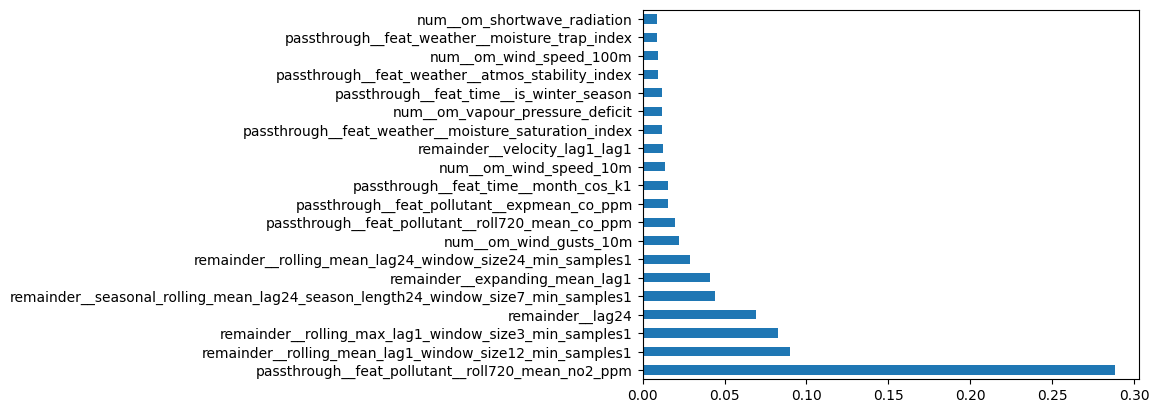

passthrough__feat_pollutant__roll720_mean_no2_ppm                                   0.288255
remainder__rolling_mean_lag1_window_size12_min_samples1                             0.089755
remainder__rolling_max_lag1_window_size3_min_samples1                               0.082367
remainder__lag24                                                                    0.069051
remainder__seasonal_rolling_mean_lag24_season_length24_window_size7_min_samples1    0.044365
remainder__expanding_mean_lag1                                                      0.040915
remainder__rolling_mean_lag24_window_size24_min_samples1                            0.028646
num__om_wind_gusts_10m                                                              0.022285
passthrough__feat_pollutant__roll720_mean_co_ppm                                    0.019502
passthrough__feat_pollutant__expmean_co_ppm                                         0.015771
passthrough__feat_time__month_cos_k1                                  

In [45]:
# ---------------------------------------------------------------------
# FIT AND SAVE THE FINAL MODEL

fcst.fit(
    train_ts,
    static_features=CustomXGBoostModel.STATIC_COLUMNS,
    # weight_col="y_weight_penalty",
)

wrapper = fcst.models_[MODEL_NAME]

# # Access the model inside the pipeline
inner_pipeline = wrapper.pipeline
model = inner_pipeline.named_steps['model']
preprocessor = inner_pipeline.named_steps['preprocessor']

importance = model.feature_importances_
names = preprocessor.get_feature_names_out()

# Sort and plot the top 20
feat_importances = pd.Series(importance, index=names)
feat_importances.nlargest(20).plot(kind='barh')
plt.show()

display(feat_importances.nlargest(500))

In [46]:
with tempfile.TemporaryDirectory() as tmpdir:
    save_dir = os.path.join(cfg.DATA_EXPORT_PATH, 'models', MODEL_NAME+'_v1')
    fcst.save(save_dir)

#### Features correlation

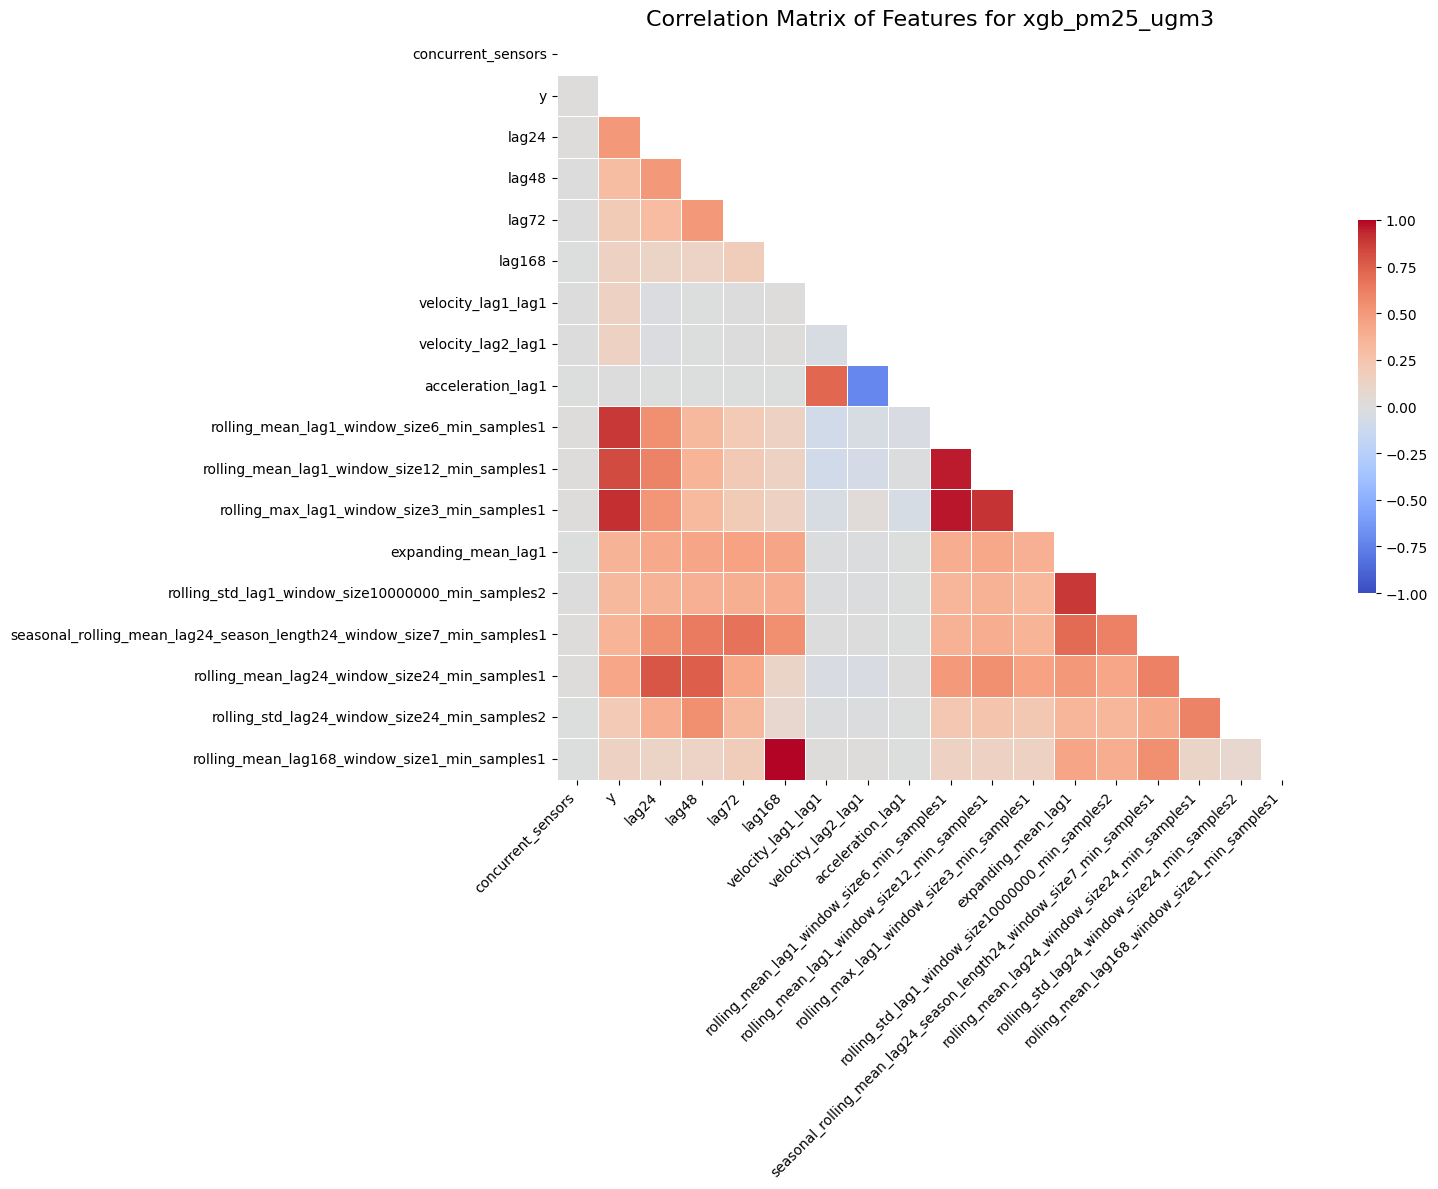

--- Top 50 Highly Correlated Feature Pairs ---
rolling_max_lag1_window_size3_min_samples1                             rolling_mean_lag1_window_size6_min_samples1                              0.965686
rolling_mean_lag1_window_size6_min_samples1                            rolling_max_lag1_window_size3_min_samples1                               0.965686
                                                                       rolling_mean_lag1_window_size12_min_samples1                             0.958334
rolling_mean_lag1_window_size12_min_samples1                           rolling_mean_lag1_window_size6_min_samples1                              0.958334
y                                                                      rolling_max_lag1_window_size3_min_samples1                               0.908492
rolling_max_lag1_window_size3_min_samples1                             y                                                                        0.908492
                                   

In [69]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ================================================================
# 1. GENERATE FEATURES (PREPROCESS)
# ================================================================

prep_df = fcst.preprocess(
    train_ts,
    static_features=CustomXGBoostModel.STATIC_COLUMNS,
    dropna=True 
)

# --- FIX: Select ONLY numeric columns automatically ---
numeric_df = prep_df.select_dtypes(include=[np.number])
filtered_columns = [col for col in numeric_df.columns if not col.startswith(("feat_", "om_", "segment", "oaq_")) and not col.endswith("imputed")]
# ================================================================
# 2. CALCULATE CORRELATION MATRIX
# ================================================================

corr_matrix = numeric_df[filtered_columns].corr()

# ================================================================
# 3. PLOT HEATMAP
# ================================================================

plt.figure(figsize=(16, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

heatmap = sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap='coolwarm',
    vmax=1,
    vmin=-1,
    center=0,
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .5},
    annot=False
)

plt.title(f'Correlation Matrix of Features for {MODEL_NAME}', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ================================================================
# 4. PRINT HIGHLY CORRELATED PAIRS (> 0.95)
# ================================================================

corr_pairs = corr_matrix.abs().unstack()
corr_pairs = corr_pairs.sort_values(ascending=False)
corr_pairs = corr_pairs[corr_pairs < 1.0] 

print("--- Top 50 Highly Correlated Feature Pairs ---")
print(corr_pairs.head(50))

In [ ]:
# # CHECK WHICH UNIQUE_IDS WERE DROPPED DURING PREPROCESSING 

# # 1. Run the preprocessing step explicitly
# # This mimics exactly what happens inside .fit()
# processed_df = fcst.preprocess(
#     train_ts,
#     static_features=CustomXGBoostModel.STATIC_COLUMNS
# )

# # 2. Compare the IDs in the processed data vs original data
# surviving_ids = set(processed_df['unique_id'].unique())
# original_ids = set(train_ts['unique_id'].unique())

# dropped_ids = original_ids - surviving_ids

# print(f"Count dropped: {len(dropped_ids)}")
# print(list(dropped_ids))

In [10]:
# ---------------------------------------------------------------------
# CLEAR MEMORY

train_df = None
del train_df

train_ts = None
del train_ts
fcst = None
del fcst
cv_result = None
del cv_result
evaluation = None
del evaluation

unreachable = gc.collect()

## Predictions

### Load the prediction data

In [7]:
custom_xgb = CustomXGBoostModel()

# BigQuery
start_time = time.perf_counter()
query = """
    SELECT
        *
    FROM `openaq-anomaly-prediction.dev_serving.ml_seoul__xgb_features_predictions`
    WHERE datetimeto_utc >= '2024-08-01 15:00:00'
      AND datetimeto_utc <= '2026-01-05 15:00:00'
      AND location_id IN UNNEST(@safe_location_ids)
    ORDER BY location_id, datetimeto_utc ASC
"""
query_parameters = [
    ("safe_location_ids", "STRING", KEPT_LOCATIONS),
]
history_df = bq.query(query, query_parameters=query_parameters, dry_run=False, debug=True)
custom_xgb.categorize_columns(history_df)

# ================================================================
# INTERPOLATE ALL POLLUTANTS
 
history_df = custom_xgb.interpolate_pollutants(history_df, debug=True)
custom_xgb.print_nan_report(history_df)


# ================================================================
# COLUMNS CATEGORIZATION
 
display(history_df.head(5))
# custom_xgb.print_categories_report()

21:32:07      DEBUG |  > [BigQuery]: Request finished in 14.21s  ->  1,403,248 rows, 1320.84 MB
INTERPOLATING 6 POLLUTANTS
----------------------------------------------------------------
BEFORE: 1324053 total NaN values
    -> Adding columns       : ['pm25_ugm3_is_imputed', 'pm10_ugm3_is_imputed', 'no2_ppm_is_imputed', 'o3_ppm_is_imputed', 'so2_ppm_is_imputed', 'co_ppm_is_imputed', 'any_imputed']
    -> Grouped by           : ['location_id', 'segment_id']
    -> Linear interpolation : up to 4 hours
    -> Forward fill         : up to 4 hours
    -> Backward fill        : up to 4 hours
AFTER: 1143126 total NaN values

[ TARGET    ]: 1143126 NaN values in the target columns
pm25_ugm3    201277
pm10_ugm3    195659
o3_ppm       188027
so2_ppm      187207
co_ppm       185657
no2_ppm      185299
dtype: int64

[ OPENAQ    ]: 0 NaN values in OpenAQ columns
[ OPENMETEO ]: 0 NaN values in OpenMeteo columns
[ FEATURES  ]: 1262249 NaN values in features columns
feat_pollutant__roll720_mean_pm25_u

,location_id,datetimeto_utc,concurrent_sensors,segment_id,segment_start,segment_end,segment_perfect_hours,segment_total_hours,segment_perfect_density,segment_tier,segments_num,segments_total,pm25_ugm3,pm10_ugm3,no2_ppm,o3_ppm,so2_ppm,co_ppm,oaq_datetimeto_local,oaq_ismonitor,oaq_owner_id,oaq_provider_id,oaq_latitude,oaq_longitude,om_elevation,om_temperature_2m,om_relative_humidity_2m,om_dew_point_2m,om_precipitation,om_rain,om_snowfall,om_snow_depth,om_shortwave_radiation,om_direct_radiation,om_diffuse_radiation,om_weather_code,om_pressure_msl,om_cloud_cover,om_cloud_cover_low,om_cloud_cover_mid,om_cloud_cover_high,om_vapour_pressure_deficit,om_wind_speed_100m,om_wind_speed_10m,om_wind_gusts_10m,om_is_day,feat_time__hour,feat_time__dow,feat_time__month,feat_time__hour_sin_k1,feat_time__hour_cos_k1,feat_time__hour_sin_k2,feat_time__hour_cos_k2,feat_time__hour_sin_k3,feat_time__hour_cos_k3,feat_time__dow_sin_k1,feat_time__dow_cos_k1,feat_time__month_sin_k1,feat_time__month_cos_k1,feat_time__is_rush_hour,feat_time__is_weekend,feat_time__is_party_night,feat_time__is_evening_transition,feat_time__is_yellow_dust_season,feat_time__is_moonsoon_season,feat_time__is_winter_season,feat_time__is_summer_break,feat_time__is_winter_break,feat_time__is_spring_break,feat_time__is_school_break,feat_pollutant__expmean_pm25_ugm3,feat_pollutant__expmean_pm10_ugm3,feat_pollutant__expmean_no2_ppm,feat_pollutant__expmean_o3_ppm,feat_pollutant__expmean_so2_ppm,feat_pollutant__expmean_co_ppm,feat_pollutant__roll720_mean_pm25_ugm3,feat_pollutant__roll720_mean_pm10_ugm3,feat_pollutant__roll720_mean_no2_ppm,feat_pollutant__roll720_mean_o3_ppm,feat_pollutant__roll720_mean_so2_ppm,feat_pollutant__roll720_mean_co_ppm,feat_weather__wind_u_10m,feat_weather__wind_v_10m,feat_weather__wind_shear_100m_10m,feat_weather__cooling_rate_1h,feat_weather__stagnation_cooling_index,feat_weather__washout_index,feat_weather__moisture_trap_index,feat_weather__atmos_stability_index,feat_weather__moisture_saturation_index,feat_weather__dew_point_depression,feat_weather__photolytic_flux_index,feat_weather__wind_burst_ratio_index_10m,feat_weather__lag1_precipitation,feat_weather__delta1_pressure_msl,feat_weather__delta3_temperature_2m,pm25_ugm3_is_imputed,pm10_ugm3_is_imputed,no2_ppm_is_imputed,o3_ppm_is_imputed,so2_ppm_is_imputed,co_ppm_is_imputed,any_imputed
0,2622586,2024-08-01 15:00:00+00:00,6,2622586_serie,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,9.0,23.0,0.0145,0.0199,0.0027,0.26,2024-08-02 00:00:00,True,4,69,37.580167,127.044856,20.0,26.6,95,25.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,1005.1,23,21,6,0,0.17,6.6,2.2,6.8,0,0,4,7,0.000000,1.000000,0.000000,1.000000e+00,0.000000e+00,1.000000e+00,-0.433884,-0.900969,-0.5,-0.866025,0,0,0,1,0,1,0,1,0,0,1,15.038086,29.055118,0.020902,0.039328,0.002996,0.419236,11.782421,21.600289,0.016818,0.030747,0.002572,0.361023,-2.172914,-3.441558e-01,4.4,-0.4,-0.181818,0.0,43402.045455,456.863636,3.703704,0.8,0.0,3.090909,0.0,-0.2,-1.3,0,0,0,0,0,0,0
1,2622586,2024-08-01 16:00:00+00:00,6,2622586_serie,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,11.0,21.0,0.0107,0.0210,0.0029,0.23,2024-08-02 01:00:00,True,4,69,37.580167,127.044856,20.0,26.3,97,25.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,1005.0,28,22,11,0,0.10,6.4,2.5,5.0,0,1,4,7,0.258819,0.965926,0.500000,8.660254e-01,7.071068e-01,7.071068e-01,-0.433884,-0.900969,-0.5,-0.866025,0,0,0,0,0,1,0,1,0,0,1,15.035283,29.052315,0.020899,0.039319,0.002996,0.419163,11.785303,21.614719,0.016820,0.030757,0.002572,0.360994,-2.500000,-4.592425e-16,3.9,-0.3,-0.120000,0.0,38994.000000,402.000000,5.000000,0.5,0.0,2.000000,0.0,-0.1,-1.1,0,0,0,0,0,0,0
2,2622586,2024-08-01 17:00:00+00:00,6,2622586_serie,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,11.0,23.0,0.0101,0.0204,0.0029,0.22,2024-08-02 02:00:00,True,4,69,37.580167,127.044856,20.0,26.1,97,25.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,1004.5,27,15,0,14,0.10,5.4,2.3,5.8,0,2,4,7,0.500000,0.866025,0.866025,5.000000e-01,1.000000e+00,6.123234e-17,-0.433884,-0.900969,-0.5,-0.866025,0,0,0,0,0,1,0,1,0,0,1,

### Make a prediction

In [52]:
# ================================================================
# PARAMETERS

TARGET_COL = "pm25_ugm3"
# TARGET_COL = "pm10_ugm3"
# TARGET_COL = "no2_ppm"
# TARGET_COL = "o3_ppm"
# TARGET_COL = "so2_ppm"
# TARGET_COL = "co_ppm"
MODEL_NAME = "xgb_" + TARGET_COL

CUTOFF_DATE_END = pd.Timestamp("2025-12-23 15:00:00", tz="UTC")
STARTING_DATE = CUTOFF_DATE_END - pd.Timedelta(days=7*4)  # 4 weeks back
# ================================================================
# CREATE new_df and X_df

# Prep the dataframe
history_ts = custom_xgb.prepare_timeseries_dataframe(history_df, TARGET_COL)
fcst = custom_xgb.create_mlforecaster(history_ts, TARGET_COL)  # history_ts to have the full columns

# ---------------------------------------------------------------------

HISTORY_MASK = (history_ts["ds"] <= CUTOFF_DATE_END) & (history_ts["ds"] >= STARTING_DATE)

# Historical data up to cutoff date
new_data = history_ts[HISTORY_MASK].copy().ffill().bfill()
display(new_data["y"].isna().sum())

# Exogenous features for prediction period (minus the target column)
X_df = history_ts[history_ts["ds"] > CUTOFF_DATE_END].drop(columns=["y"]+CustomXGBoostModel.STATIC_COLUMNS).copy()
# new_df: dataframe with historical data
print(f"new_data range : {new_data['ds'].min()}  ->  {new_data['ds'].max()}")
print(f"X_df range     : {X_df['ds'].min()}  ->  {X_df['ds'].max()}")


MLForecast Burn-in Calculation
----------------------------------------------------------------
Target Transform Cost: 0h
Max Lag Feature Cost: 10000001h
Total Rows Lost (Burn-in): 10000001h (416666.7083333333 days)
Rows remaining for training: -9999497h/504 (-416645.71 days)



np.int64(0)

new_data range : 2025-11-25 15:00:00+00:00  ->  2025-12-23 15:00:00+00:00
X_df range     : 2025-12-23 16:00:00+00:00  ->  2025-12-31 15:00:00+00:00


/tmp/ipykernel_2722/4103575430.py:40: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  locations_df = comparison_df.groupby("location_id").agg(


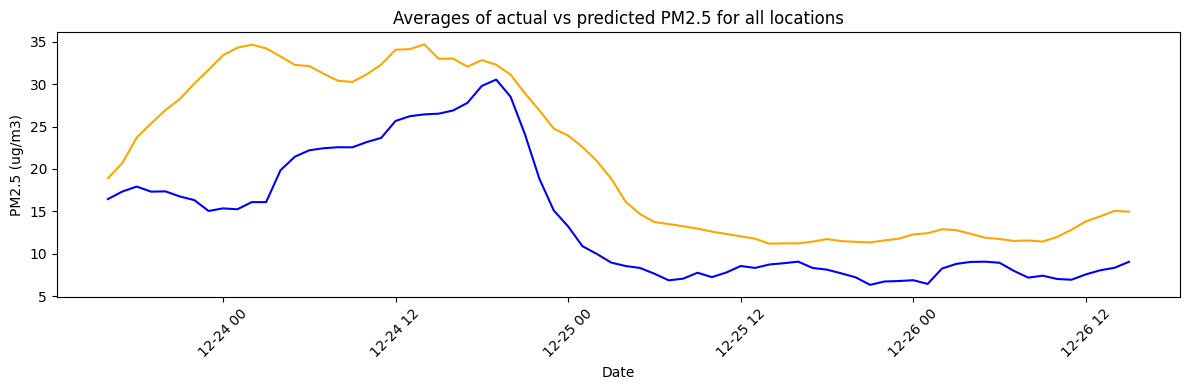

Global RMSE: 9.98
Avg Location RMSE: 9.70


In [53]:
# ================================================================
# LOAD the model and make predictions

save_dir = os.path.join(cfg.DATA_EXPORT_PATH, 'models', MODEL_NAME+'_v1')
loaded_fcst = MLForecast.load(save_dir)

preds = loaded_fcst.predict(
    72,
    new_df=new_data,
    X_df=X_df,
)

# ================================================================
# MERGE the predictions with actuals for evaluation

actuals = history_ts[history_ts["ds"] >= CUTOFF_DATE_END]
comparison_df = actuals.merge(
    preds,
    on=["unique_id", "ds"],
    suffixes=("_actual", "_predicted"),
)

# ---------------------------------------------------------------------
# EVALUATE the predictions



comparison_df["error_abs"] = (comparison_df["y"] - comparison_df[MODEL_NAME]).abs()
comparison_df["error_sq"]  = (comparison_df["y"] - comparison_df[MODEL_NAME]) ** 2


# SMAPE (Symmetric Mean Absolute Percentage Error)
# Range: 0% to 200%. Handles zeros better than standard MAPE.
numerator = comparison_df["error_abs"]
denominator = (comparison_df["y"].abs() + comparison_df[MODEL_NAME].abs())
comparison_df["smape_raw"] = 2 * numerator / denominator


# 2. Group by Location
locations_df = comparison_df.groupby("location_id").agg(
    MAE=("error_abs", "mean"),       # Mean Absolute Error
    MSE=("error_sq", "mean"),        # Mean Squared Error (temp for RMSE)
    SMAPE=("smape_raw", "mean"),     # Relative Error (Scale Independent)
    Count=("y", "count")             # Check for sparse data
).reset_index()


# 3. Finalize Metrics
locations_df["RMSE"] = np.sqrt(locations_df["MSE"])  # Root Mean Squared Error
locations_df["SMAPE"] = locations_df["SMAPE"] * 100  # Convert to Percentage
locations_df.drop(columns=["MSE"], inplace=True)     # Cleanup
locations_df.head(5)

# comparison_df["error_pct"] = comparison_df["error_abs"] / comparison_df["y"].replace(0, np.nan) * 100
# display(comparison_df.head(10))

# ---------------------------------------------------------------------

average_df = comparison_df.groupby("ds")[["y", MODEL_NAME]].agg(
    y_actual=("y", "mean"),
    y_predicted=(MODEL_NAME, "mean"),
).reset_index()
# display(average_df.head(10))

fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(average_df, x="ds", y="y_actual", color="blue", legend=True, ax=ax)
sns.lineplot(average_df, x="ds", y="y_predicted", color="orange", legend=True, ax=ax)
ax.set_title(f"Averages of actual vs predicted PM2.5 for all locations")
ax.set_xlabel("Date")
ax.set_ylabel("PM2.5 (ug/m3)")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------

# 1. Your current metric (Global RMSE) - Heavily weighted by polluted sites
global_rmse = np.sqrt(comparison_df["error_sq"].mean())

# 2. Average Location RMSE - Treats every location equally
average_location_rmse = locations_df["RMSE"].mean()

print(f"Global RMSE: {global_rmse:.2f}")
print(f"Avg Location RMSE: {average_location_rmse:.2f}")

In [ ]:
import matplotlib.dates as mdates  # <--- Essential Import

# 4. Sort to find Best/Worst
# # Sort by SMAPE is usually best for comparing different sensors
best_locations = locations_df[locations_df["Count"] > 0].sort_values("RMSE", ascending=True)
worst_locations = locations_df[locations_df["Count"] > 0].sort_values("RMSE", ascending=False)


best_locations_ids = best_locations["location_id"].tolist()
worst_locations_ids = worst_locations["location_id"].tolist()

# best_locations_ids = locations_df[locations_df["error_abs_sum"] != 0].sort_values("error_abs_sum", ascending=False)["location_id"].tolist()
# worst_locations_ids = locations_df[locations_df["error_abs_sum"] != 0].sort_values("error_abs_sum", ascending=True)["location_id"].tolist()

MAX_IDS = 4
random_ids = random.sample(
    comparison_df["location_id"].unique().tolist(),
    MAX_IDS,
)

selected_ids = random_ids
# selected_ids = best_locations_ids[:MAX_IDS]
# selected_ids = worst_locations_ids[:MAX_IDS]

hour_fmt = mdates.DateFormatter('%H:%M')
fig, axes = plt.subplots(nrows=MAX_IDS, ncols=1, figsize=(8, MAX_IDS * 3), squeeze=False)
for i, loc_id in enumerate(selected_ids):
    sns.lineplot(comparison_df[comparison_df["location_id"] == loc_id], x="oaq_datetimeto_local", y="y", color="blue", legend=True, ax=axes[i, 0])
    sns.lineplot(comparison_df[comparison_df["location_id"] == loc_id], x="oaq_datetimeto_local", y=MODEL_NAME, color="orange", legend=True, ax=axes[i, 0])
    axes[i, 0].set_title(f"Location ID: {loc_id}")
    axes[i, 0].set_xlabel("Date")
    axes[i, 0].xaxis.set_major_formatter(hour_fmt)
    axes[i, 0].set_ylabel("PM2.5 (ug/m3)")
    axes[i, 0].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### Automate

In [10]:
# TARGET_COL = "pm25_ugm3"
# # TARGET_COL = "pm10_ugm3"
# # TARGET_COL = "no2_ppm"
# # TARGET_COL = "o3_ppm"
# # TARGET_COL = "so2_ppm"
# # TARGET_COL = "co_ppm"
# MODEL_NAME = "xgb_" + TARGET_COL
    
# save_dir = os.path.join(cfg.DATA_EXPORT_PATH, 'models', MODEL_NAME+'_v1')
# loaded_fcst = MLForecast.load(save_dir)

# final_df = pd.DataFrame()

# # for pred_date in pd.date_range(start="2025-11-01 15:00:00", end="2025-12-30 15:00:00", freq="D", tz="UTC"):
# for pred_date in pd.date_range(start="2025-11-01 15:00:00", end="2025-11-03 15:00:00", freq="D", tz="UTC"):

#     CUTOFF_DATE_END = pred_date
#     STARTING_DATE = pred_date - pd.Timedelta(days=7*4)  # 4 weeks back
#     # print(f"Processing predictions for date: {pred_date}  =>  from {STARTING_DATE} to {CUTOFF_DATE_END}")
    
#     # CUTOFF_DATE_END = pd.Timestamp("2025-12-23 15:00:00", tz="UTC")
#     # STARTING_DATE = CUTOFF_DATE_END - pd.Timedelta(days=7*4)  # 4 weeks back
    
#     # ================================================================
#     # CREATE new_df and X_df

#     # Prep the dataframe
#     history_ts = custom_xgb.prepare_timeseries_dataframe(history_df, TARGET_COL)
#     fcst = custom_xgb.create_mlforecaster(history_ts, TARGET_COL)  # history_ts to have the full columns

#     # ---------------------------------------------------------------------

#     HISTORY_MASK = (history_ts["ds"] <= CUTOFF_DATE_END) & (history_ts["ds"] >= STARTING_DATE)

#     # Historical data up to cutoff date
#     new_data = history_ts[HISTORY_MASK].copy().ffill().bfill()
#     # display(new_data["y"].isna().sum())

#     # Exogenous features for prediction period (minus the target column)
#     X_df = history_ts[history_ts["ds"] > CUTOFF_DATE_END].drop(columns=["y"]+CustomXGBoostModel.STATIC_COLUMNS).copy()
#     # new_df: dataframe with historical data
#     # print(f"new_data range : {new_data['ds'].min()}  ->  {new_data['ds'].max()}")
#     # print(f"X_df range     : {X_df['ds'].min()}  ->  {X_df['ds'].max()}")
    
#     # ================================================================
#     # LOAD the model and make predictions



#     preds = loaded_fcst.predict(
#         24,
#         new_df=new_data,
#         X_df=X_df,
#     )

#     # ================================================================
#     # MERGE the predictions with actuals for evaluation

#     actuals = history_ts[history_ts["ds"] >= CUTOFF_DATE_END]
#     comparison_df = actuals.merge(
#         preds,
#         on=["unique_id", "ds"],
#         suffixes=("_actual", "_predicted"),
#     )

#     # ---------------------------------------------------------------------
#     # EVALUATE the predictions

#     comparison_df["error_abs"] = (comparison_df["y"] - comparison_df[MODEL_NAME]).abs()
#     comparison_df["error_sq"]  = (comparison_df["y"] - comparison_df[MODEL_NAME]) ** 2

#     # SMAPE (Symmetric Mean Absolute Percentage Error)
#     # Range: 0% to 200%. Handles zeros better than standard MAPE.
#     numerator = comparison_df["error_abs"]
#     denominator = (comparison_df["y"].abs() + comparison_df[MODEL_NAME].abs())
#     comparison_df["smape_raw"] = 2 * numerator / denominator


#     # 2. Group by Location
#     locations_df = comparison_df.groupby("location_id").agg(
#         MAE=("error_abs", "mean"),       # Mean Absolute Error
#         MSE=("error_sq", "mean"),        # Mean Squared Error (temp for RMSE)
#         SMAPE=("smape_raw", "mean"),     # Relative Error (Scale Independent)
#         Count=("y", "count")             # Check for sparse data
#     ).reset_index()


#     # 3. Finalize Metrics
#     locations_df["RMSE"] = np.sqrt(locations_df["MSE"])  # Root Mean Squared Error
#     locations_df["SMAPE"] = locations_df["SMAPE"] * 100  # Convert to Percentage
#     locations_df.drop(columns=["MSE"], inplace=True)     # Cleanup
#     locations_df.head(5)

#     # comparison_df["error_pct"] = comparison_df["error_abs"] / comparison_df["y"].replace(0, np.nan) * 100
#     # display(comparison_df.head(10))

#     # ---------------------------------------------------------------------

#     # average_df = comparison_df.groupby("ds")[["y", MODEL_NAME]].agg(
#     #     y_actual=("y", "mean"),
#     #     y_predicted=(MODEL_NAME, "mean"),
#     # ).reset_index()
#     # # display(average_df.head(10))

#     # fig, ax = plt.subplots(figsize=(12, 4))
#     # sns.lineplot(average_df, x="ds", y="y_actual", color="blue", legend=True, ax=ax)
#     # sns.lineplot(average_df, x="ds", y="y_predicted", color="orange", legend=True, ax=ax)
#     # ax.set_title(f"Averages of actual vs predicted PM2.5 for all locations")
#     # ax.set_xlabel("Date")
#     # ax.set_ylabel("PM2.5 (ug/m3)")
#     # ax.tick_params(axis='x', rotation=45)
#     # plt.tight_layout()
#     # plt.show()

#     # ---------------------------------------------------------------------

#     # 1. Your current metric (Global RMSE) - Heavily weighted by polluted sites
#     global_rmse = np.sqrt(comparison_df["error_sq"].mean())

#     # 2. Average Location RMSE - Treats every location equally
#     average_location_rmse = locations_df["RMSE"].mean()

#     print(f"Global RMSE: {global_rmse:.2f}")
#     print(f"Avg Location RMSE: {average_location_rmse:.2f}")
    
#     final_df = pd.concat([final_df, comparison_df], axis=0)
        

In [48]:
warnings.filterwarnings("ignore", message="The default of observed=False is deprecated and will be changed")

TARGET_COL = "pm25_ugm3"
TARGET_COL = "pm10_ugm3"
TARGET_COL = "no2_ppm"
TARGET_COL = "o3_ppm"
TARGET_COL = "so2_ppm"
TARGET_COL = "co_ppm"
MODEL_NAME = "xgb_" + TARGET_COL

# ================================================================
# 1. SETUP (Do this ONCE, outside the loop)
# ================================================================

# Prep the dataframe once to save time
history_ts = custom_xgb.prepare_timeseries_dataframe(history_df, TARGET_COL)
loaded_fcst = MLForecast.load(save_dir)

# List to store daily prediction dataframes
all_preds_list = []

# ================================================================
# 2. ROLLING PREDICTION LOOP
# ================================================================

date_range = pd.date_range(start="2025-11-01 15:00:00", end="2026-01-02 15:00:00", freq="D", tz="UTC")
# date_range = pd.date_range(start="2025-12-29 15:00:00", end="2025-12-31 15:00:00", freq="D", tz="UTC")

for pred_date in date_range:
    
    CUTOFF_DATE_END = pred_date
    STARTING_DATE = pred_date - pd.Timedelta(days=28) # 4 weeks back
    
    # --- A. Prepare Input Data ---
    # History mask: Use data from [Current Date - 28 Days] to [Current Date]
    history_mask = (history_ts["ds"] <= CUTOFF_DATE_END) & (history_ts["ds"] >= STARTING_DATE)
    
    new_data = history_ts[history_mask].copy().ffill().bfill()
    # new_data = history_ts[history_mask].copy().interpolate(method="linear", limit=limit, limit_direction="both").ffill().bfill()
    # new_data = history_ts[history_mask].copy()
    # new_data["y"] = new_data["y"].interpolate(method="linear", limit_direction="both").ffill().bfill()
    
    # Future mask: Exogenous features for the next 72h
    # Note: drop Y and Statics for X_df
    X_df = history_ts[history_ts["ds"] > CUTOFF_DATE_END].drop(
        columns=["y"] + CustomXGBoostModel.STATIC_COLUMNS, errors='ignore'
    ).copy()

    # --- B. Predict ---
    preds = loaded_fcst.predict(
        72,
        new_df=new_data,
        X_df=X_df,
    )
    
    # --- C. CRITICAL STEP: Tag the prediction ---
    # We add the 'cutoff_date' so we know WHEN this prediction was made.
    preds["cutoff_date"] = CUTOFF_DATE_END
    
    all_preds_list.append(preds)

# # ================================================================
# # 3A. CONSOLIDATE AND KEEP "FRESHEST"
# # ================================================================

# # 1. Combine all chunks
# raw_final_df = pd.concat(all_preds_list, axis=0)

# # 2. Sort by 'ds' (Target Time) and 'cutoff_date' (Generation Time)
# # We sort 'cutoff_date' DESCENDING so the newest prediction comes first.
# raw_final_df = raw_final_df.sort_values(by=["unique_id", "ds", "cutoff_date"], ascending=[True, True, False])

# # 3. Drop Duplicates
# # Since we sorted by cutoff_date DESC, the first occurrence is the "Freshest".
# final_predictions = raw_final_df.drop_duplicates(subset=["unique_id", "ds"], keep="first").copy()


# # ================================================================
# # 4A. FINAL EVALUATION
# # ================================================================

# # Now merge with actuals ONCE for the whole period
# actuals = history_ts[history_ts["ds"].isin(final_predictions["ds"])].copy()

# comparison_df = actuals.merge(
#     final_predictions,
#     on=["unique_id", "ds"],
#     suffixes=("_actual", "_predicted"),
# )

# # Calculate Errors
# comparison_df["error_sq"] = (comparison_df["y"] - comparison_df[MODEL_NAME]) ** 2
# comparison_df["error_abs"] = (comparison_df["y"] - comparison_df[MODEL_NAME]).abs()

# print(f"Total Rows Evaluated: {len(comparison_df)}")
# print(f"Global RMSE: {np.sqrt(comparison_df['error_sq'].mean()):.2f}")

# display(comparison_df.head())

# ================================================================
# 3B. CONSOLIDATE AND KEEP "BEST" (LOWEST ERROR) (ORACLE BIAS)
# ================================================================

# 1. Combine all chunks
raw_final_df = pd.concat(all_preds_list, axis=0)

# 2. Merge with Actuals IMMEDIATELY (to calculate error for every candidate)
# We need the 'y' column to judge which prediction was best.
raw_eval_df = raw_final_df.merge(
    history_ts[["unique_id", "ds", "y"]], 
    on=["unique_id", "ds"], 
    how="left"
)

# 3. Calculate Absolute Error for every single prediction instance
raw_eval_df["abs_diff"] = (raw_eval_df["y"] - raw_eval_df[MODEL_NAME]).abs()

# 4. Sort by Error (Ascending)
# logic: For every unique_id/ds pair, put the one with the smallest error at the top
best_predictions_df = raw_eval_df.sort_values(
    by=["unique_id", "ds", "abs_diff"], 
    ascending=[True, True, True] # Smallest error first
)

# 5. Drop Duplicates
# Since we sorted by Error ASC, the "First" one is the most accurate one.
final_predictions = best_predictions_df.drop_duplicates(subset=["unique_id", "ds"], keep="first").copy()

# ================================================================
# 4B. FINAL EVALUATION
# ================================================================

# No need to merge actuals again, they are already there
comparison_df = final_predictions.copy()

# Calculate Squared Error for metrics
comparison_df["error_sq"] = comparison_df["abs_diff"] ** 2

print(f"Total Rows Evaluated: {len(comparison_df)}")
print(f"Global RMSE (Oracle/Best Case): {np.sqrt(comparison_df['error_sq'].mean()):.2f}")

display(comparison_df.head())

Total Rows Evaluated: 174720
Global RMSE (Oracle/Best Case): 0.13


,unique_id,ds,xgb_co_ppm,cutoff_date,y,abs_diff,error_sq
0,2622586_serie,2025-11-01 16:00:00+00:00,0.428001,2025-11-01 15:00:00+00:00,0.38,0.048001,0.002304
1,2622586_serie,2025-11-01 17:00:00+00:00,0.445677,2025-11-01 15:00:00+00:00,0.40,0.045677,0.002086
2,2622586_serie,2025-11-01 18:00:00+00:00,0.483686,2025-11-01 15:00:00+00:00,0.41,0.073686,0.005430
3,2622586_serie,2025-11-01 19:00:00+00:00,0.507326,2025-11-01 15:00:00+00:00,0.38,0.127326,0.016212
4,2622586_serie,2025-11-01 20:00:00+00:00,0.513727,2025-11-01 15:00:00+00:00,0.37,0.143727,0.020657


In [49]:
saved_path = os.path.join(cfg.DATA_EXPORT_PATH, f'{MODEL_NAME}_best_predictions_v1.parquet')
comparison_df.to_parquet(saved_path, index=False, compression='snappy')

In [ ]:
# Concatenate manually all files

dataframes_names = [
    "xgb_co_ppm_best_predictions_v1.parquet",
    "xgb_no2_ppm_best_predictions_v1.parquet",
    "xgb_o3_ppm_best_predictions_v1.parquet",
    "xgb_pm10_ugm3_best_predictions_v1.parquet",
    "xgb_pm25_ugm3_best_predictions_v1.parquet",
]

# full_df = pd.DataFrame()
for df_name in dataframes_names:
    print(os.path.join(cfg.DATA_EXPORT_PATH, df_name))

    temp_df = pd.read_parquet(os.path.join(cfg.DATA_EXPORT_PATH, df_name))
    if "xgb_co_ppm_best_predictions_v1":
        y = "co_ppm"
        y_pred = "xgb_co_ppm"
        location_id = temp_df["unique_id"].str.split("_").str[0]
        temp_df["location_id"] = location_id
        temp_df = temp_df.rename(
            columns={
                "y": f"{y}",
                y_pred: f"{y}_pred",
            }
        )
        temp_df = temp_df.drop(columns=["unique_id", "cutoff_date", "abs_diff", "error_sq"])
        temp_df = temp_df[["location_id", "ds", f"{y}", f"{y}_pred"]]
        display(temp_df.head())
        break

/home/deniscck/code/openaq-anomaly-prediction/data/export/xgb_co_ppm_best_predictions_v1.parquet


,location_id,ds,co_ppm,co_ppm_pred
0,2622586,2025-11-01 16:00:00+00:00,0.38,0.428001
1,2622586,2025-11-01 17:00:00+00:00,0.40,0.445677
2,2622586,2025-11-01 18:00:00+00:00,0.41,0.483686
3,2622586,2025-11-01 19:00:00+00:00,0.38,0.507326
4,2622586,2025-11-01 20:00:00+00:00,0.37,0.513727


In [ ]:
import pandas as pd
import os
import re
from functools import reduce

dataframes_names = [
    "xgb_co_ppm_best_predictions_v1.parquet",
    "xgb_no2_ppm_best_predictions_v1.parquet",
    "xgb_o3_ppm_best_predictions_v1.parquet",
    "xgb_pm10_ugm3_best_predictions_v1.parquet",
    "xgb_pm25_ugm3_best_predictions_v1.parquet",
    # Add your 6th file here if missing
]

processed_dfs = []

for df_name in dataframes_names:
    file_path = os.path.join(cfg.DATA_EXPORT_PATH, df_name)
    temp_df = pd.read_parquet(file_path)
    
    # 1. Dynamically extract pollutant name from filename
    # Removes "xgb_" prefix and "_best_predictions_v1.parquet" suffix
    # Example: "xgb_co_ppm_best..." becomes "co_ppm"
    pollutant_name = df_name.replace("xgb_", "").split("_best_predictions")[0]
    
    # 2. Extract location_id from unique_id
    temp_df["location_id"] = temp_df["unique_id"].str.split("_").str[0]
    
    # 3. Rename columns dynamically
    # We assume the 'y' column is the actual value
    # We assume the prediction column in the parquet usually matches the extracted name or follows a pattern
    # Based on your snippet, the prediction col seems to be "xgb_" + pollutant_name
    pred_col_original = f"xgb_{pollutant_name}" 
    
    rename_map = {
        "y": pollutant_name,                 # e.g., "co_ppm"
        pred_col_original: f"{pollutant_name}_pred" # e.g., "co_ppm_pred"
    }
    
    temp_df = temp_df.rename(columns=rename_map)
    
    # 4. Filter columns to keep only what we need for the merge
    cols_to_keep = ["location_id", "ds", pollutant_name, f"{pollutant_name}_pred"]
    temp_df = temp_df[cols_to_keep]
    
    # 5. Append to list
    processed_dfs.append(temp_df)

# 6. Merge all dataframes in the list
# We use 'reduce' to merge DF1 with DF2, then the result with DF3, etc.
final_df = reduce(
    lambda left, right: pd.merge(left, right, on=['location_id', 'ds'], how='outer'), 
    processed_dfs
)

# ---------------------------------------------------------------------

anomalies_df = pd.read_parquet(
    os.path.join(cfg.DATA_EXPORT_PATH, 'anomalies_top_100pct_contributors.parquet')
)
anomalies_keys = anomalies_df[['location_id', 'timestamp']].drop_duplicates()
anomalies_keys = anomalies_keys.rename(columns={'timestamp': 'ds'})
print(f"Anomalies count (anomalies df): {len(anomalies_keys)}")
# 3. Create the flag column (set all existing rows to True)
anomalies_keys['is_anomaly'] = True

# 4. Perform a Left Merge
# We merge final_df with anomalies_keys. 
# Rows found in anomalies_keys will get 'True', others will get 'NaN'
final_df = final_df.merge(
    anomalies_keys, 
    on=['location_id', 'ds'], 
    how='left'
)

final_df['is_anomaly'] = final_df['is_anomaly'].fillna(False).astype(bool)

# Display result
# display(final_df.head())
print(f"Anomalies found (in the final df): {final_df['is_anomaly'].sum()}")

# ---------------------------------------------------------------------

# Display result
print(f"Final shape: {final_df.shape}")
display(final_df.head())



Anomalies count (anomalies df): 2968
Anomalies found (in the final df): 2968
Final shape: (174720, 13)


/tmp/ipykernel_24613/1466903614.py:76: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  final_df['is_anomaly'] = final_df['is_anomaly'].fillna(False).astype(bool)


,location_id,ds,co_ppm,co_ppm_pred,no2_ppm,no2_ppm_pred,o3_ppm,o3_ppm_pred,pm10_ugm3,pm10_ugm3_pred,pm25_ugm3,pm25_ugm3_pred,is_anomaly
0,2622586,2025-11-01 16:00:00+00:00,0.38,0.428001,0.0159,0.027212,0.0270,0.027923,12.0,18.684185,9.0,10.658287,False
1,2622586,2025-11-01 17:00:00+00:00,0.40,0.445677,0.0161,0.025460,0.0226,0.022899,9.0,20.940538,5.0,11.477976,False
2,2622586,2025-11-01 18:00:00+00:00,0.41,0.483686,0.0168,0.022582,0.0214,0.019403,8.0,19.667749,4.0,11.317117,False
3,2622586,2025-11-01 19:00:00+00:00,0.38,0.507326,0.0173,0.021569,0.0180,0.018541,9.0,18.563381,4.0,11.284904,False
4,2622586,2025-11-01 20:00:00+00:00,0.37,0.513727,0.0129,0.021515,0.0273,0.017219,10.0,18.115095,5.0,11.364037,False


In [8]:
history_df.head()

,location_id,datetimeto_utc,concurrent_sensors,segment_id,segment_start,segment_end,segment_perfect_hours,segment_total_hours,segment_perfect_density,segment_tier,segments_num,segments_total,pm25_ugm3,pm10_ugm3,no2_ppm,o3_ppm,so2_ppm,co_ppm,oaq_datetimeto_local,oaq_ismonitor,oaq_owner_id,oaq_provider_id,oaq_latitude,oaq_longitude,om_elevation,om_temperature_2m,om_relative_humidity_2m,om_dew_point_2m,om_precipitation,om_rain,om_snowfall,om_snow_depth,om_shortwave_radiation,om_direct_radiation,om_diffuse_radiation,om_weather_code,om_pressure_msl,om_cloud_cover,om_cloud_cover_low,om_cloud_cover_mid,om_cloud_cover_high,om_vapour_pressure_deficit,om_wind_speed_100m,om_wind_speed_10m,om_wind_gusts_10m,om_is_day,feat_time__hour,feat_time__dow,feat_time__month,feat_time__hour_sin_k1,feat_time__hour_cos_k1,feat_time__hour_sin_k2,feat_time__hour_cos_k2,feat_time__hour_sin_k3,feat_time__hour_cos_k3,feat_time__dow_sin_k1,feat_time__dow_cos_k1,feat_time__month_sin_k1,feat_time__month_cos_k1,feat_time__is_rush_hour,feat_time__is_weekend,feat_time__is_party_night,feat_time__is_evening_transition,feat_time__is_yellow_dust_season,feat_time__is_moonsoon_season,feat_time__is_winter_season,feat_time__is_summer_break,feat_time__is_winter_break,feat_time__is_spring_break,feat_time__is_school_break,feat_pollutant__expmean_pm25_ugm3,feat_pollutant__expmean_pm10_ugm3,feat_pollutant__expmean_no2_ppm,feat_pollutant__expmean_o3_ppm,feat_pollutant__expmean_so2_ppm,feat_pollutant__expmean_co_ppm,feat_pollutant__roll720_mean_pm25_ugm3,feat_pollutant__roll720_mean_pm10_ugm3,feat_pollutant__roll720_mean_no2_ppm,feat_pollutant__roll720_mean_o3_ppm,feat_pollutant__roll720_mean_so2_ppm,feat_pollutant__roll720_mean_co_ppm,feat_weather__wind_u_10m,feat_weather__wind_v_10m,feat_weather__wind_shear_100m_10m,feat_weather__cooling_rate_1h,feat_weather__stagnation_cooling_index,feat_weather__washout_index,feat_weather__moisture_trap_index,feat_weather__atmos_stability_index,feat_weather__moisture_saturation_index,feat_weather__dew_point_depression,feat_weather__photolytic_flux_index,feat_weather__wind_burst_ratio_index_10m,feat_weather__lag1_precipitation,feat_weather__delta1_pressure_msl,feat_weather__delta3_temperature_2m,pm25_ugm3_is_imputed,pm10_ugm3_is_imputed,no2_ppm_is_imputed,o3_ppm_is_imputed,so2_ppm_is_imputed,co_ppm_is_imputed,any_imputed
0,2622586,2024-08-01 15:00:00+00:00,6,2622586_serie,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,9.0,23.0,0.0145,0.0199,0.0027,0.26,2024-08-02 00:00:00,True,4,69,37.580167,127.044856,20.0,26.6,95,25.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,1005.1,23,21,6,0,0.17,6.6,2.2,6.8,0,0,4,7,0.000000,1.000000,0.000000,1.000000e+00,0.000000e+00,1.000000e+00,-0.433884,-0.900969,-0.5,-0.866025,0,0,0,1,0,1,0,1,0,0,1,15.038086,29.055118,0.020902,0.039328,0.002996,0.419236,11.782421,21.600289,0.016818,0.030747,0.002572,0.361023,-2.172914,-3.441558e-01,4.4,-0.4,-0.181818,0.0,43402.045455,456.863636,3.703704,0.8,0.0,3.090909,0.0,-0.2,-1.3,0,0,0,0,0,0,0
1,2622586,2024-08-01 16:00:00+00:00,6,2622586_serie,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,11.0,21.0,0.0107,0.0210,0.0029,0.23,2024-08-02 01:00:00,True,4,69,37.580167,127.044856,20.0,26.3,97,25.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,1005.0,28,22,11,0,0.10,6.4,2.5,5.0,0,1,4,7,0.258819,0.965926,0.500000,8.660254e-01,7.071068e-01,7.071068e-01,-0.433884,-0.900969,-0.5,-0.866025,0,0,0,0,0,1,0,1,0,0,1,15.035283,29.052315,0.020899,0.039319,0.002996,0.419163,11.785303,21.614719,0.016820,0.030757,0.002572,0.360994,-2.500000,-4.592425e-16,3.9,-0.3,-0.120000,0.0,38994.000000,402.000000,5.000000,0.5,0.0,2.000000,0.0,-0.1,-1.1,0,0,0,0,0,0,0
2,2622586,2024-08-01 17:00:00+00:00,6,2622586_serie,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,11.0,23.0,0.0101,0.0204,0.0029,0.22,2024-08-02 02:00:00,True,4,69,37.580167,127.044856,20.0,26.1,97,25.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,1004.5,27,15,0,14,0.10,5.4,2.3,5.8,0,2,4,7,0.500000,0.866025,0.866025,5.000000e-01,1.000000e+00,6.123234e-17,-0.433884,-0.900969,-0.5,-0.866025,0,0,0,0,0,1,0,1,0,0,1,

In [18]:
# --- 1. Prepare DataFrames (Type & Key Alignment) ---
# Rename timestamp in history_df to match final_df
history_df = history_df.rename(columns={"datetimeto_utc": "ds"})

# Force key columns to identical types to prevent merge failures
history_df["location_id"] = history_df["location_id"].astype(str)
history_df["ds"] = pd.to_datetime(history_df["ds"])

final_df["location_id"] = final_df["location_id"].astype(str)
final_df["ds"] = pd.to_datetime(final_df["ds"])

# --- 2. Perform the Merge ---
# Left Merge: Keep all rows from history_df, add predictions where available
# suffixes=('', '_check') marks redundant columns from final_df with '_check'
master_df = pd.merge(
    history_df,
    final_df,
    on=["location_id", "ds"],
    how="left",
    suffixes=("", "_check")
)

# --- 3. Clean Up (The "Correct Changes") ---
# Since diagnostic confirmed 100% matches, we drop the redundant '_check' columns
# cols_to_drop = [col for col in master_df.columns if col.endswith('_check')]
# master_df = master_df.drop(columns=cols_to_drop)

# Handle cases where history has rows but final_df didn't (missing predictions)
# We fill NaN in 'is_anomaly' with False (assuming no prediction = no anomaly detected)
if 'is_anomaly' in master_df.columns:
    master_df['is_anomaly'] = master_df['is_anomaly'].fillna(False).astype(bool)

# --- 4. Organize Columns ---
# Reorder so predictions sit next to actuals
# Define the preferred order for the main columns
preferred_order = [
    'location_id', 'ds', 'is_anomaly',
    'co_ppm', 'co_ppm_pred',
    'no2_ppm', 'no2_ppm_pred',
    'o3_ppm', 'o3_ppm_pred',
    'pm10_ugm3', 'pm10_ugm3_pred',
    'pm25_ugm3', 'pm25_ugm3_pred'
]

# Identify columns present in master_df that are in our preferred list
existing_preferred = [c for c in preferred_order if c in master_df.columns]

# identify the rest of the columns (weather, other features)
remaining_cols = [c for c in master_df.columns if c not in existing_preferred]

# Combine: Preferred + Remaining
master_df = master_df[existing_preferred + remaining_cols]

# --- 5. Final Output ---
print(f"Final Master DataFrame Shape: {master_df.shape}")
display(master_df.head())

master_df.to_parquet(
    os.path.join(cfg.DATA_EXPORT_PATH, 'all_best_predictions_v1.parquet'), 
    index=False, 
    compression='snappy'
)   

/tmp/ipykernel_24613/3120150357.py:31: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  master_df['is_anomaly'] = master_df['is_anomaly'].fillna(False).astype(bool)


Final Master DataFrame Shape: (1403248, 115)


,location_id,ds,is_anomaly,co_ppm,co_ppm_pred,no2_ppm,no2_ppm_pred,o3_ppm,o3_ppm_pred,pm10_ugm3,pm10_ugm3_pred,pm25_ugm3,pm25_ugm3_pred,concurrent_sensors,segment_id,segment_start,segment_end,segment_perfect_hours,segment_total_hours,segment_perfect_density,segment_tier,segments_num,segments_total,so2_ppm,oaq_datetimeto_local,oaq_ismonitor,oaq_owner_id,oaq_provider_id,oaq_latitude,oaq_longitude,om_elevation,om_temperature_2m,om_relative_humidity_2m,om_dew_point_2m,om_precipitation,om_rain,om_snowfall,om_snow_depth,om_shortwave_radiation,om_direct_radiation,om_diffuse_radiation,om_weather_code,om_pressure_msl,om_cloud_cover,om_cloud_cover_low,om_cloud_cover_mid,om_cloud_cover_high,om_vapour_pressure_deficit,om_wind_speed_100m,om_wind_speed_10m,om_wind_gusts_10m,om_is_day,feat_time__hour,feat_time__dow,feat_time__month,feat_time__hour_sin_k1,feat_time__hour_cos_k1,feat_time__hour_sin_k2,feat_time__hour_cos_k2,feat_time__hour_sin_k3,feat_time__hour_cos_k3,feat_time__dow_sin_k1,feat_time__dow_cos_k1,feat_time__month_sin_k1,feat_time__month_cos_k1,feat_time__is_rush_hour,feat_time__is_weekend,feat_time__is_party_night,feat_time__is_evening_transition,feat_time__is_yellow_dust_season,feat_time__is_moonsoon_season,feat_time__is_winter_season,feat_time__is_summer_break,feat_time__is_winter_break,feat_time__is_spring_break,feat_time__is_school_break,feat_pollutant__expmean_pm25_ugm3,feat_pollutant__expmean_pm10_ugm3,feat_pollutant__expmean_no2_ppm,feat_pollutant__expmean_o3_ppm,feat_pollutant__expmean_so2_ppm,feat_pollutant__expmean_co_ppm,feat_pollutant__roll720_mean_pm25_ugm3,feat_pollutant__roll720_mean_pm10_ugm3,feat_pollutant__roll720_mean_no2_ppm,feat_pollutant__roll720_mean_o3_ppm,feat_pollutant__roll720_mean_so2_ppm,feat_pollutant__roll720_mean_co_ppm,feat_weather__wind_u_10m,feat_weather__wind_v_10m,feat_weather__wind_shear_100m_10m,feat_weather__cooling_rate_1h,feat_weather__stagnation_cooling_index,feat_weather__washout_index,feat_weather__moisture_trap_index,feat_weather__atmos_stability_index,feat_weather__moisture_saturation_index,feat_weather__dew_point_depression,feat_weather__photolytic_flux_index,feat_weather__wind_burst_ratio_index_10m,feat_weather__lag1_precipitation,feat_weather__delta1_pressure_msl,feat_weather__delta3_temperature_2m,pm25_ugm3_is_imputed,pm10_ugm3_is_imputed,no2_ppm_is_imputed,o3_ppm_is_imputed,so2_ppm_is_imputed,co_ppm_is_imputed,any_imputed,co_ppm_check,no2_ppm_check,o3_ppm_check,pm10_ugm3_check,pm25_ugm3_check
0,2622586,2024-08-01 15:00:00+00:00,False,0.26,NaN,0.0145,NaN,0.0199,NaN,23.0,NaN,9.0,NaN,6,2622586_serie,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0.0027,2024-08-02 00:00:00,True,4,69,37.580167,127.044856,20.0,26.6,95,25.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,1005.1,23,21,6,0,0.17,6.6,2.2,6.8,0,0,4,7,0.000000,1.000000,0.000000,1.000000e+00,0.000000e+00,1.000000e+00,-0.433884,-0.900969,-0.5,-0.866025,0,0,0,1,0,1,0,1,0,0,1,15.038086,29.055118,0.020902,0.039328,0.002996,0.419236,11.782421,21.600289,0.016818,0.030747,0.002572,0.361023,-2.172914,-3.441558e-01,4.4,-0.4,-0.181818,0.0,43402.045455,456.863636,3.703704,0.8,0.0,3.090909,0.0,-0.2,-1.3,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
1,2622586,2024-08-01 16:00:00+00:00,False,0.23,NaN,0.0107,NaN,0.0210,NaN,21.0,NaN,11.0,NaN,6,2622586_serie,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0.0029,2024-08-02 01:00:00,True,4,69,37.580167,127.044856,20.0,26.3,97,25.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,1005.0,28,22,11,0,0.10,6.4,2.5,5.0,0,1,4,7,0.258819,0.965926,0.500000,8.660254e-01,7.071068e-01,7.071068e-01,-0.433884,-0.900969,-0.5,-0.866025,0,0,0,0,0,1,0,1,0,0,1,15.035283,29.052315,0.020899,0.039319,0.002996,0.419163,11.785303,21.614719,0.016820,0.030757,0.002572,0.360994,-2.500000,-4.592425e-16,3.9,-0.3,-0.120000,0.0,38994.000000,402.000000,5.000000,0.5,0.0,2.000000,0.0,-0.1,-1.1,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
2,2622586,2024-08-01 17:00:00+00:00,False,0.22,NaN,0.0101,NaN,0.0204,NaN,23.0,NaN,11.0,NaN,6,2622586_serie,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0.0029,2024-08-0

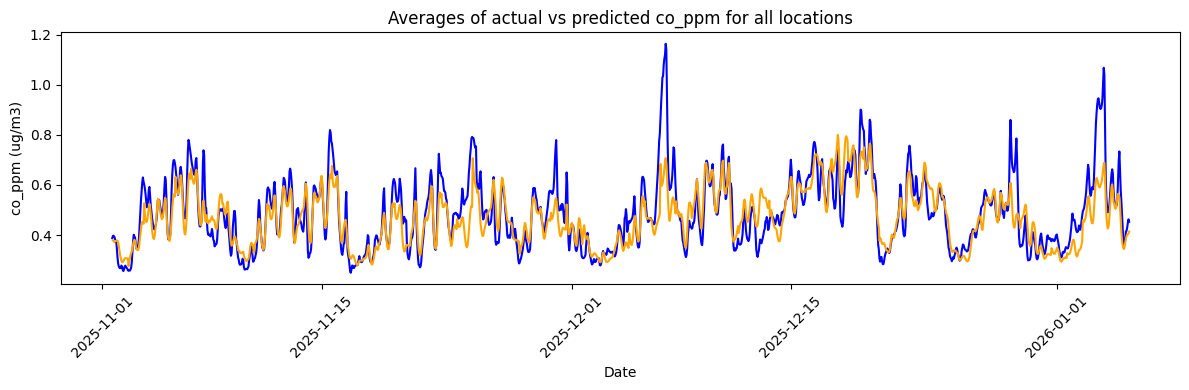

In [17]:
test_pollutant = "co_ppm"

average_df = master_df.groupby("ds")[[test_pollutant, f"{test_pollutant}_pred"]].agg(
    y_actual=(test_pollutant, "mean"),
    y_predicted=(f"{test_pollutant}_pred", "mean"),
).reset_index()
# display(average_df.head(10))

date_mask = (average_df["ds"] >= pd.Timestamp("2025-11-01 15:00:00", tz="UTC"))


fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(average_df[date_mask], x="ds", y="y_actual", color="blue", legend=True, ax=ax)
sns.lineplot(average_df[date_mask], x="ds", y="y_predicted", color="orange", legend=True, ax=ax)
ax.set_title(f"Averages of actual vs predicted {test_pollutant} for all locations")
ax.set_xlabel("Date")
ax.set_ylabel(f"{test_pollutant} (ug/m3)")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# 3A: 11.71, 72h, fresh selection, start at 15:00 UTC
# 3B: 10.91, 72h, best selection (oracle bias), start at 15:00 UTC
# 3B: 11.45, 72h, best selection (oracle bias), shifted to start at 1:00 AM UTC
# 3B: 11.42, 72h, best selection (oracle bias), shifted to start at 1:00 AM UTC, NEW FEATURES (wind+cooling rate etc)
# 3B: 10.67, 72h, best selection (oracle bias), shifted to start at 15:00 UTC, NEW FEATURES (wind+cooling rate etc)

# FORBIDDEN TECHNIQUE: combining BOTH tweedie with log1p
# 3B: 9.87, WITH LOG1P 72h, best selection (oracle bias), shifted to start at 15:00 UTC, NEW FEATURES (wind+cooling rate etc)

# Check: log1p with squared error (same RMSE)
# 3B: 9.87, WITH LOG1P 72h, best selection (oracle bias), shifted to start at 15:00 UTC, NEW FEATURES (wind+cooling rate etc)

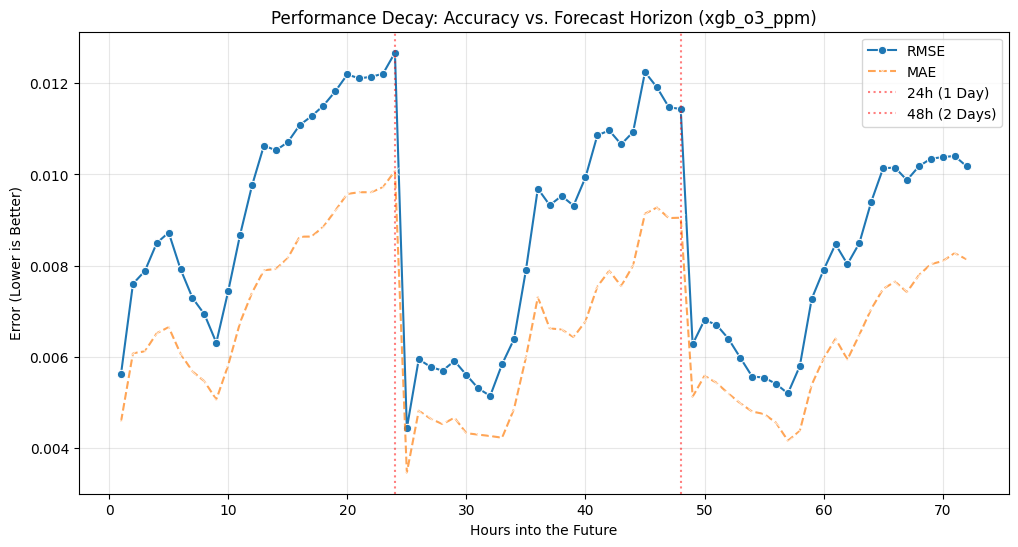

Average RMSE for Day 1 (1-24h): 0.00964907484264514
Average RMSE for Day 3 (49-72h): 0.007956219466950461


In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Ensure Errors are Calculated ---
# Re-calculate these to be 100% sure they exist in the dataframe
comparison_df["error_sq"] = (comparison_df["y"] - comparison_df[MODEL_NAME]) ** 2
comparison_df["error_abs"] = (comparison_df["y"] - comparison_df[MODEL_NAME]).abs()

# 1. Calculate the "Horizon Step" for each row
# Logic: We know the 'cutoff_date'. The 'ds' is the target.
# Horizon = (Target - Cutoff) in hours.
comparison_df["horizon_hours"] = (
    (comparison_df["ds"] - comparison_df["cutoff_date"]).dt.total_seconds() / 3600
).astype(int)

# 2. Group errors by Horizon
horizon_metrics = comparison_df.groupby("horizon_hours").agg(
    RMSE=("error_sq", lambda x: np.sqrt(x.mean())),  # Root Mean Squared Error
    MAE=("error_abs", "mean"),                       # Mean Absolute Error
    Count=("error_abs", "count")                     # Make sure we have enough data
).reset_index()

# 3. Plot Error vs. Horizon
plt.figure(figsize=(12, 6))

# Plot RMSE
sns.lineplot(data=horizon_metrics, x="horizon_hours", y="RMSE", marker="o", label="RMSE")
# Optional: Plot MAE to see if it follows the same trend
sns.lineplot(data=horizon_metrics, x="horizon_hours", y="MAE", marker="x", linestyle="--", alpha=0.7, label="MAE")

# Add "Day" markers
plt.axvline(x=24, color='red', linestyle=':', alpha=0.5, label="24h (1 Day)")
plt.axvline(x=48, color='red', linestyle=':', alpha=0.5, label="48h (2 Days)")

plt.title(f"Performance Decay: Accuracy vs. Forecast Horizon ({MODEL_NAME})")
plt.xlabel("Hours into the Future")
plt.ylabel("Error (Lower is Better)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 4. Print Summary Stats
print("Average RMSE for Day 1 (1-24h):", horizon_metrics[horizon_metrics['horizon_hours'] <= 24]['RMSE'].mean())
print("Average RMSE for Day 3 (49-72h):", horizon_metrics[horizon_metrics['horizon_hours'] > 48]['RMSE'].mean())

Total Rows Evaluated: 174720
Total Rows Evaluated: 174720
Global RMSE: 0.13


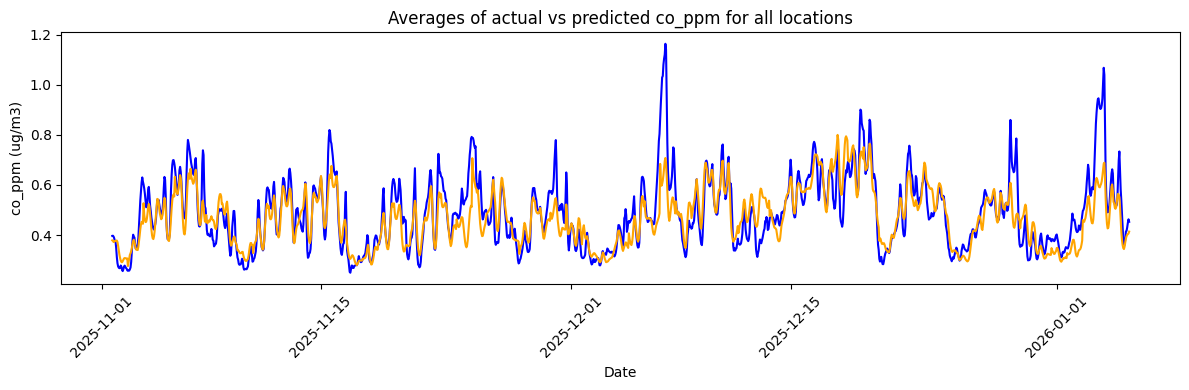

In [65]:
# 72h preds with new config (velocity, acceleration, new wind), no short term lags
# COMPLETE ffill/bfill in new_df

print(f"Total Rows Evaluated: {len(comparison_df)}")
print(f"Total Rows Evaluated: {len(comparison_df)}")
print(f"Global RMSE: {np.sqrt(comparison_df['error_sq'].mean()):.2f}")

average_df = comparison_df.groupby("ds")[["y", MODEL_NAME]].agg(
    y_actual=("y", "mean"),
    y_predicted=(MODEL_NAME, "mean"),
).reset_index()
# display(average_df.head(10))

date_mask = (average_df["ds"] <= pd.Timestamp("2025-12-01 15:00:00", tz="UTC"))


fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(average_df, x="ds", y="y_actual", color="blue", legend=True, ax=ax)
sns.lineplot(average_df, x="ds", y="y_predicted", color="orange", legend=True, ax=ax)
ax.set_title(f"Averages of actual vs predicted {TARGET_COL} for all locations")
ax.set_xlabel("Date")
ax.set_ylabel(f"{TARGET_COL} (ug/m3)")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

Total Rows Evaluated: 88704
Global RMSE: 11.85


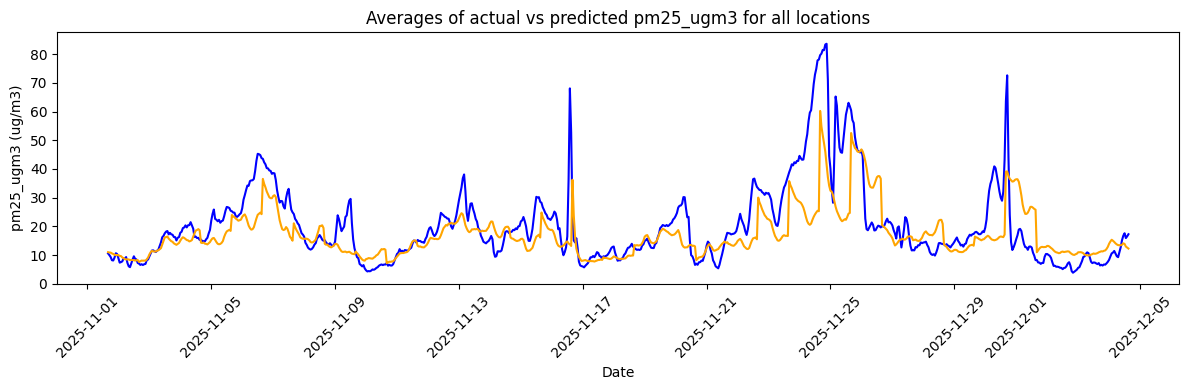

In [35]:
# 72h preds with FULL short term lags [1,2,3] + rolling means [-2,-6]
# TARGET Y: interpolation 72h limit + ffill/bfill (in new_df)

print(f"Total Rows Evaluated: {len(comparison_df)}")
print(f"Global RMSE: {np.sqrt(comparison_df['error_sq'].mean()):.2f}")

average_df = comparison_df.groupby("ds")[["y", MODEL_NAME]].agg(
    y_actual=("y", "mean"),
    y_predicted=(MODEL_NAME, "mean"),
).reset_index()
# display(average_df.head(10))

fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(average_df, x="ds", y="y_actual", color="blue", legend=True, ax=ax)
sns.lineplot(average_df, x="ds", y="y_predicted", color="orange", legend=True, ax=ax)
ax.set_title(f"Averages of actual vs predicted {TARGET_COL} for all locations")
ax.set_xlabel("Date")
ax.set_ylabel(f"{TARGET_COL} (ug/m3)")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

Total Rows Evaluated: 88704
Global RMSE: 12.01


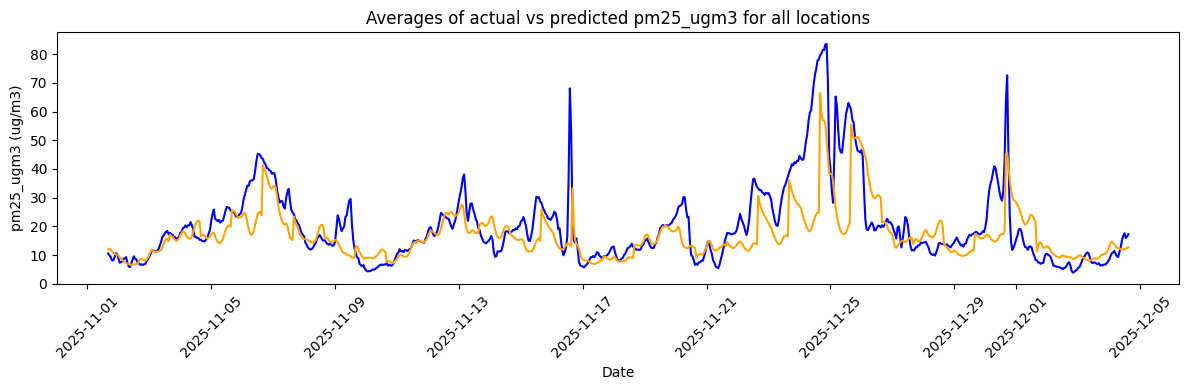

In [61]:
# 72h preds with only lag2 [2, 24+] + rolling means [-2,-6]
# COMPLETE ffill/bfill in new_df

print(f"Total Rows Evaluated: {len(comparison_df)}")
print(f"Global RMSE: {np.sqrt(comparison_df['error_sq'].mean()):.2f}")

average_df = comparison_df.groupby("ds")[["y", MODEL_NAME]].agg(
    y_actual=("y", "mean"),
    y_predicted=(MODEL_NAME, "mean"),
).reset_index()
# display(average_df.head(10))

fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(average_df, x="ds", y="y_actual", color="blue", legend=True, ax=ax)
sns.lineplot(average_df, x="ds", y="y_predicted", color="orange", legend=True, ax=ax)
ax.set_title(f"Averages of actual vs predicted {TARGET_COL} for all locations")
ax.set_xlabel("Date")
ax.set_ylabel(f"{TARGET_COL} (ug/m3)")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

Total Rows Evaluated: 88704
Global RMSE: 11.84


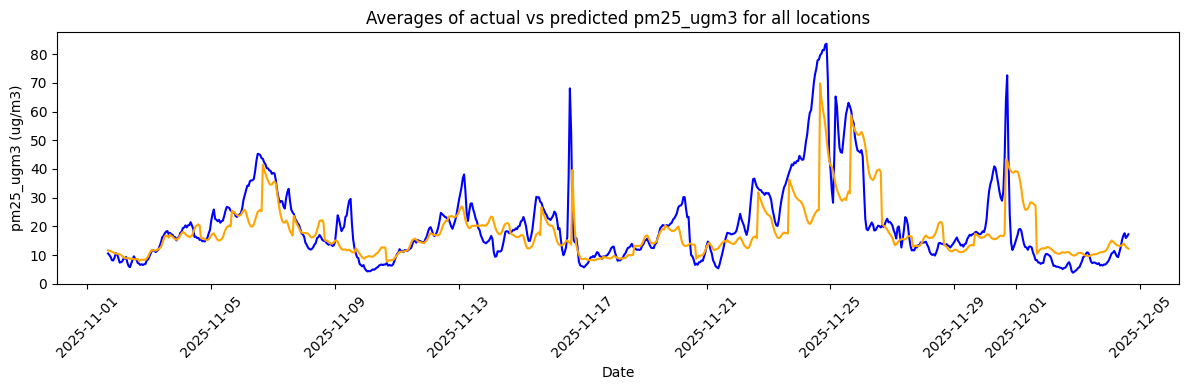

In [ ]:
# 72h preds with FULL short term lags [1,2,3] + rolling means [-2,-6]
# COMPLETE ffill/bfill in new_df

print(f"Total Rows Evaluated: {len(comparison_df)}")
print(f"Global RMSE: {np.sqrt(comparison_df['error_sq'].mean()):.2f}")

average_df = comparison_df.groupby("ds")[["y", MODEL_NAME]].agg(
    y_actual=("y", "mean"),
    y_predicted=(MODEL_NAME, "mean"),
).reset_index()
# display(average_df.head(10))

fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(average_df, x="ds", y="y_actual", color="blue", legend=True, ax=ax)
sns.lineplot(average_df, x="ds", y="y_predicted", color="orange", legend=True, ax=ax)
ax.set_title(f"Averages of actual vs predicted {TARGET_COL} for all locations")
ax.set_xlabel("Date")
ax.set_ylabel(f"{TARGET_COL} (ug/m3)")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

#### Old records

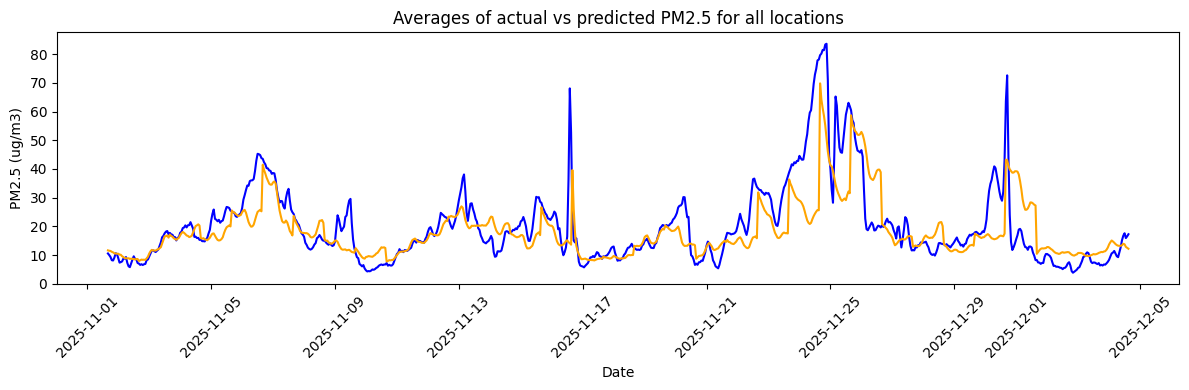

In [13]:
# 72h preds with FULL short term lags [1,2,3] + rolling means [-2,-6]
average_df = comparison_df.groupby("ds")[["y", MODEL_NAME]].agg(
    y_actual=("y", "mean"),
    y_predicted=(MODEL_NAME, "mean"),
).reset_index()
# display(average_df.head(10))

fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(average_df, x="ds", y="y_actual", color="blue", legend=True, ax=ax)
sns.lineplot(average_df, x="ds", y="y_predicted", color="orange", legend=True, ax=ax)
ax.set_title(f"Averages of actual vs predicted PM2.5 for all locations")
ax.set_xlabel("Date")
ax.set_ylabel("PM2.5 (ug/m3)")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

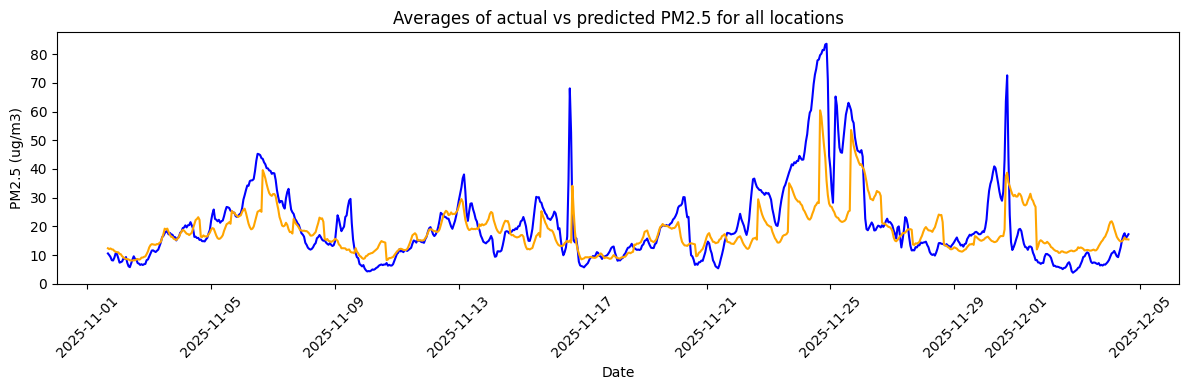

In [81]:
# 24h preds
average_df = comparison_df.groupby("ds")[["y", MODEL_NAME]].agg(
    y_actual=("y", "mean"),
    y_predicted=(MODEL_NAME, "mean"),
).reset_index()
# display(average_df.head(10))

fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(average_df, x="ds", y="y_actual", color="blue", legend=True, ax=ax)
sns.lineplot(average_df, x="ds", y="y_predicted", color="orange", legend=True, ax=ax)
ax.set_title(f"Averages of actual vs predicted PM2.5 for all locations")
ax.set_xlabel("Date")
ax.set_ylabel("PM2.5 (ug/m3)")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

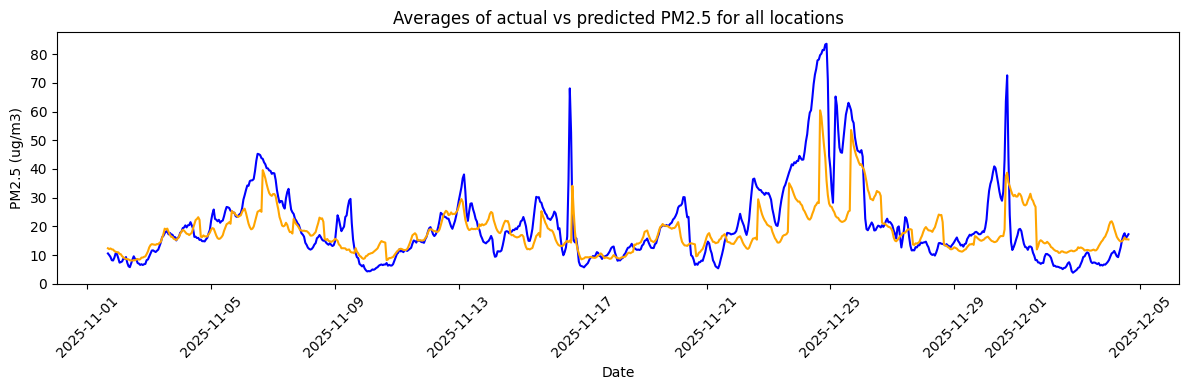

In [ ]:
# 72h preds
average_df = comparison_df.groupby("ds")[["y", MODEL_NAME]].agg(
    y_actual=("y", "mean"),
    y_predicted=(MODEL_NAME, "mean"),
).reset_index()
# display(average_df.head(10))

fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(average_df, x="ds", y="y_actual", color="blue", legend=True, ax=ax)
sns.lineplot(average_df, x="ds", y="y_predicted", color="orange", legend=True, ax=ax)
ax.set_title(f"Averages of actual vs predicted PM2.5 for all locations")
ax.set_xlabel("Date")
ax.set_ylabel("PM2.5 (ug/m3)")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [69]:
# print(final_df.shape)
# print(final_df["ds"].nunique())
# display(final_df.head())

In [27]:
average_df = comparison.groupby("ds")[["y", MODEL_NAME]].agg(
    y_actual=("y", "mean"),
    y_predicted=(MODEL_NAME, "mean"),
).reset_index()
# display(average_df.head(10))

fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(average_df, x="ds", y="y_actual", color="blue", legend=True, ax=ax)
sns.lineplot(average_df, x="ds", y="y_predicted", color="orange", legend=True, ax=ax)
ax.set_title(f"Averages of actual vs predicted PM2.5 for all locations")
ax.set_xlabel("Date")
ax.set_ylabel("PM2.5 (ug/m3)")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

NameError: name 'comparison' is not defined